## CS328 Assignment 2: Human Activity Recognition Using Machine Learning

The objective of this assignment is to develop your understanding and practical application skills in the field of machine learning, particularly focusing on Human Activity Recognition (HAR). Human Activity Recognition has become increasingly important in various fields including health care, personal fitness, smart homes, and surveillance. In this assignment, you will be working with the accelerometer data the class collected with Sensor Logger in the Activities Study, plus a small sample dataset recorded with a wrist-worn device. The data has been classified into seven distinct activities: walking, walking downstairs, running/jogging, lying, sitting, standing, and walking upstairs.

You will get hands-on experience in several key aspects of machine learning and data processing:
1. Data collection and preprocessing from multiple sources for analysis
2. Understand how to create windows of raw data through resampling and to extract meaningful features from these windows.
3. Hands-on experience on how to extract features, encode target variables, split datasets, train models, make predictions, and evaluate the performance of these models.
4. Learn to assess your trained model’s performance using common metrics like accuracy, confusion matrix and more. Understanding how well your models are performing is crucial in any machine learning task.

Through this assignment, you will be able to develop a pipeline for Human Activity Recognition that can be further fine-tuned for different tasks or datasets. You will be able to apply the skills and knowledge gained here to other machine learning projects and real-world applications.

#### Imports Block

Make sure all imports are in this block below (and leave the two comments IMPORTS START and IMPORT END as is. The extractor script uses the START and END delimitors when extracting the functions).

In [1]:
# -- IMPORTS START --
import pandas as pd
import glob
import re
import os
import sys
import json
import pickle
import datetime
import numpy as np
import matplotlib.pyplot as plt

from datetime import datetime
from sklearn import tree, metrics
from sklearn.model_selection import train_test_split, cross_val_score, GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, f1_score
from scipy.signal import butter, filtfilt, find_peaks
from scipy.stats import skew, kurtosis
from sklearn.tree import DecisionTreeClassifier,export_graphviz
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from util import viz_tree, calc_magnitude, remove_noise, add_features
# -- IMPORTS END --

# enable zooming into graphs
%matplotlib inline
plt.rcParams['figure.figsize'] = [9, 6] # width, height in inches
os.makedirs('figures', exist_ok=True)
RESULTS = {}   # every number quoted in the exploration report is stored here and written to results.json


#### About the data (read this before you start)

- **Class_Data** was recorded with Sensor Logger. Its `Accelerometer` sensor reports **linear acceleration in m/s² with gravity removed**: the phone combines the accelerometer and gyroscope to estimate the gravity vector and subtracts it from the raw signal. A phone lying still on a table reads ≈ 0 on all three axes, not 9.8.
- **Sample_Data** was recorded with a wrist-worn device. It has already been converted to match Class_Data (from *g* to m/s², and gravity removed), so both datasets are in the same units.
- Most phones log at ~100 Hz, but a few class recordings are at 50-60 Hz. Estimate the sampling rate of each file from its timestamps instead of hard-coding it.
- The column order differs between the two folders (`time,x,y,z` vs `time,seconds_elapsed,z,y,x`), so always select columns by name.

**Hint (why gravity matters):** with gravity removed, the orientation of the phone is lost. Lying, sitting, and standing all look like "almost no motion", so features computed on the acceleration magnitude will confuse them. Think about what is still different between these activities (e.g., how much the body sways while standing) and expect some confusion between these three classes. Walking, stairs, and jogging differ in intensity and rhythm, so frequency-domain and per-axis features are worth trying.

###  Assignment: Function 1: extract_features(data, window_sec, sample_rate, activity)

**Instructions:**
Define the `extract_features` function that extracts features from accelerometer data by applying a sliding window approach.


**Hints and Instructions:**
Use the `pandas.DataFrame.resample` function to implement the sliding window approach (it needs the time as index: `data.set_index('time').resample(f'{window_sec}s')`). Remember to use the computed features when appending to the new DataFrame.

- The function takes as arguments:
  - `data`: a DataFrame containing the `time` column, the raw `x`, `y`, `z` axes, and the filtered acceleration magnitude signal
  - `window_sec`: the window length in seconds for feature extraction
  - `sample_rate`: the sampling frequency of the accelerometer data
  - `activity`: the activity label for each window you extract
- The function will perform the following:
  - For each window in the resampled data:
    - Skip windows that are too short (e.g., fewer than 80% of `window_sec * sample_rate` samples). These are the partial windows at the start and end of a recording, or gaps in the logging.
    - Call the `add_my_features` function (Function 3) to compute features of the window
    - Add the `activity` label to the features
  - Append the computed features to a new DataFrame and return this DataFrame

In [2]:
# Function to extract windows and features
def extract_features(data, window_sec, sample_rate, activity):

    ######## TODO ###############
    # Non-overlapping windows of window_sec seconds (resample needs the time as index)
    min_samples = 0.8 * window_sec * sample_rate
    rows = []
    for _, window in data.set_index('time').resample(f'{window_sec}s'):
        # partial windows at the start/end of a recording, or gaps in the logging
        if len(window) < min_samples:
            continue
        features = add_my_features(window, sample_rate)
        features['activity'] = activity
        rows.append(features)
    frame = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
    #############################

    return frame


###  Assignment: Function 2: all_data_to_combined_csv(root, output_filename, window_sec)

This function is expected to process data collected from different activities, extract features and store everything into a combined CSV file.

**Hint and Instructions:**
Understand how the `glob`, `pandas` and `os` modules work. Understand how the `calc_magnitude` and `remove_noise` function work. The activity label is the name of the folder that contains the file, so use `os.path.basename(os.path.dirname(filename))` to extract the activity (file names such as `026.csv` or `accelerometer_<date>.csv` do not contain it).

- Write a function named `all_data_to_combined_csv(root, output_filename, window_sec)`.
- This function will process the data collected from various activities such as walking downstairs, jogging, lying, sitting, standing, walking upstairs, and walking. These activities' data are stored in different .csv files within their respective folders.
- the `root` will be the root folder of all the files.
- the `output_filename` will be the filename of the combined csv file.
- the `window_sec` will be the window length in seconds, so that you can try different window lengths.
- Use the glob module to create a list of all .csv files from each activity's directory.
- The pandas DataFrame `all_data` is initialized to store the processed data from all activities.
- The function will then loop over each activity's data file. For each file:
    - read each .csv file into a pandas DataFrame. `pd.read_csv` loads the `time` column as text, so parse it with `parse_dates=['time']` (this works once `transform_time_to_datetime` below has converted the Class_Data timestamps).
    - estimate the sampling rate of the file from its timestamps.
    - From the raw data, calculate the magnitude and remove any noise.
    - Extract the activity type for each file.
    - extract features using the `extract_features()` function.
    - add a `recording` column with the file name, so that windows can be grouped back into recordings later (majority vote and failure analysis).
    - append the feature frames into the all_data dataframe.
- Continue this process until all .csv files from all activities have been processed.
- Finally, the function writes the `all_data` DataFrame to `output_filename` and returns it.

In [3]:
def all_data_to_combined_csv(root, output_filename = 'all_data.csv', window_sec = 5):
    import os
    import sys

    ######## TODO ###############
    files = sorted(glob.glob(os.path.join(root, '*', '*.csv')))
    frames = []
    for filename in files:
        data = pd.read_csv(filename, parse_dates=['time'])
        if pd.api.types.is_numeric_dtype(data['time']):      # file not converted yet (ns since 1970)
            data['time'] = pd.to_datetime(data['time'], unit='ns')
        # column order differs between the two folders, so select by name
        data = data[['time', 'x', 'y', 'z']].dropna().sort_values('time').reset_index(drop=True)

        # sampling rate from the median timestamp step (most phones ~100 Hz, a few 50-60 Hz)
        dt = data['time'].diff().dt.total_seconds()
        sample_rate = 1.0 / dt[dt > 0].median()

        data = calc_magnitude(data)
        data = remove_noise(data, sample_rate)

        activity = os.path.basename(os.path.dirname(filename))
        frame = extract_features(data, window_sec, sample_rate, activity)
        if frame.empty:          # recording shorter than one window
            continue
        frame['recording'] = os.path.basename(filename)
        frames.append(frame)

    all_data = pd.concat(frames, ignore_index=True)
    all_data.to_csv(output_filename, index=False)
    #############################

    return all_data


###  Assignment: Function 3: add_my_features(window, sample_rate)

This is where you do your **feature engineering** (exploration report §1). The function receives one window and returns a one-row DataFrame of features.

**Hints and Instructions:**
- Start from the baseline features in `add_features` (7 statistics of the filtered magnitude, from util.py) and add your own as new columns. As provided, the function only returns the baseline, so you can run the whole notebook before writing any features.
- Ideas to try:
  - Time domain: RMS, range, interquartile range, zero-crossing rate, number of peaks per second (`find_peaks`)
  - Frequency domain: dominant frequency and spectral energy in a band (use `np.fft.rfft` on the filtered magnitude and `np.fft.rfftfreq(len(signal), 1/sample_rate)`)
  - Per axis: standard deviation of `x`, `y`, `z`, or correlation between axes
- Aim for ~5-8 features in your final pipeline. Keep the ones that help and document the ones you dropped.

In [4]:
def add_my_features(window, sample_rate):
    features = add_features(window)   # baseline: avg, max, med, min, q25, q75, std of filtered_accel_mag

    ######## TODO ###############
    mag = window['filtered_accel_mag'].to_numpy()        # low-passed (5 Hz) magnitude
    raw_mag = window['accel_mag'].to_numpy()             # unfiltered magnitude
    xyz = window[['x', 'y', 'z']].to_numpy()
    centered = mag - mag.mean()
    seconds = len(mag) / sample_rate

    # --- time domain ---
    features['rms'] = np.sqrt(np.mean(mag ** 2))
    features['zcr'] = np.sum(np.diff(np.sign(centered)) != 0) / seconds
    # steps: peaks at least 0.25 s apart that stand out by half a standard deviation
    peaks, _ = find_peaks(centered, distance=max(1, int(0.25 * sample_rate)),
                          prominence=0.5 * centered.std() + 1e-9)
    features['peaks_per_sec'] = len(peaks) / seconds

    # --- step periodicity: lag of the strongest autocorrelation peak between 0.25 s and 1.5 s ---
    ac = np.correlate(centered, centered, mode='full')[len(centered) - 1:]
    ac = ac / (ac[0] + 1e-12)
    lo, hi = int(0.25 * sample_rate), min(len(ac) - 1, int(1.5 * sample_rate))
    lag = lo + int(np.argmax(ac[lo:hi])) if hi > lo else 0
    features['step_period'] = lag / sample_rate
    features['acf_peak'] = ac[lag] if hi > lo else 0.0

    # --- frequency domain (Hann window, zero-padded FFT) ---
    nfft = max(1024, 2 ** int(np.ceil(np.log2(len(mag)))))
    freqs = np.fft.rfftfreq(nfft, 1 / sample_rate)
    power = np.abs(np.fft.rfft(centered * np.hanning(len(centered)), nfft)) ** 2
    gait = (freqs >= 0.5) & (freqs <= 5)
    features['dom_freq'] = freqs[gait][np.argmax(power[gait])]
    band = (freqs >= 0.3) & (freqs <= 5)
    p = power[band] / (power[band].sum() + 1e-12)
    features['spec_entropy'] = -(p * np.log(p + 1e-12)).sum() / np.log(len(p))
    features['low_band_frac'] = power[(freqs >= 0.3) & (freqs < 1)].sum() / (power[band].sum() + 1e-12)
    # share of the unfiltered magnitude's power above the 5 Hz cutoff (tremor, sensor noise, impacts)
    raw_c = raw_mag - raw_mag.mean()
    raw_power = np.abs(np.fft.rfft(raw_c * np.hanning(len(raw_c)), nfft)) ** 2
    features['hf_frac'] = raw_power[freqs > 5].sum() / (raw_power.sum() + 1e-12)

    # --- per axis and orientation-free 3-D motion ---
    for i, axis in enumerate('xyz'):
        features[f'std_{axis}'] = xyz[:, i].std()
    eig = np.clip(np.linalg.eigvalsh(np.cov(xyz.T)), 0, None)
    features['axis_std'] = np.sqrt(eig.sum())                      # total 3-D motion, rotation invariant
    features['pca1'] = eig.max() / (eig.sum() + 1e-12)             # how one-directional the motion is
    features['jerk_raw'] = np.sqrt(np.mean(np.sum(np.diff(xyz, axis=0) ** 2, axis=1))) * sample_rate
    features['pca2'] = np.sort(eig)[1] / (eig.sum() + 1e-12)       # flat (2-D) vs line-like vs isotropic motion

    # --- shape of the magnitude distribution ---
    features['kurt'] = kurtosis(mag)                               # spiky impacts vs smooth motion
    features['logvar'] = np.log(np.var(mag) + 1e-8)                # intensity on a log scale (rest spans decades)

    # --- what is left of orientation. Sensor Logger's gravity removal is not perfect: the residual
    #     mean and the slow (<1 Hz) drift land on the axes that are not vertical, so the per-axis
    #     split of slow motion still carries some information about how the phone is held. ---
    def butter_filter(sig, cutoff, btype):
        b, a = butter(2, cutoff / (sample_rate / 2), btype=btype)
        return filtfilt(b, a, sig, axis=0)
    slow = butter_filter(xyz, 1.0, 'lowpass')
    fast = butter_filter(xyz, min(5.0, 0.4 * sample_rate), 'highpass')
    slow_tot = np.sqrt(slow.var(axis=0).sum()) + 1e-12
    fast_tot = np.sqrt(fast.var(axis=0).sum()) + 1e-12
    var_tot = xyz.var(axis=0).sum() + 1e-12
    for i, axis in enumerate('xyz'):
        features[f'mean_{axis}'] = xyz[:, i].mean()                # residual gravity along the axis
        features[f'var_frac_{axis}'] = xyz[:, i].var() / var_tot   # share of motion on the axis
        features[f'slow_{axis}'] = slow[:, i].std()
        features[f'slow_frac_{axis}'] = slow[:, i].std() / slow_tot
    features['slow_fast_ratio'] = slow_tot / fast_tot              # sway/drift vs tremor and sensor noise
    with np.errstate(invalid='ignore', divide='ignore'):
        features['corr_yz'] = np.corrcoef(xyz[:, 1], xyz[:, 2])[0, 1]

    # --- vertical proxy: project the (5 Hz low-passed) motion on its main axis. While walking the
    #     main axis is close to vertical, whatever way the phone is rotated. Sign: largest excursion up. ---
    smooth = butter_filter(xyz - xyz.mean(axis=0), min(5.0, 0.4 * sample_rate), 'lowpass')
    w, v = np.linalg.eigh(np.cov(smooth.T))
    vert = smooth @ v[:, -1]
    if abs(vert.min()) > abs(vert.max()):
        vert = -vert
    features['vert_std'] = vert.std()
    features['vert_skew'] = skew(vert)                             # push-off (up) vs landing (down) asymmetry
    features['vert_kurt'] = kurtosis(vert)
    # gait regularity (Moe-Nilssen): autocorrelation peaks of the vertical signal between 0.3 s and 2.4 s
    vc = vert - vert.mean()
    vac = np.correlate(vc, vc, mode='full')[len(vc) - 1:]
    vac = vac / (vac[0] + 1e-12)
    lo, hi = int(0.3 * sample_rate), min(len(vac) - 1, int(2.4 * sample_rate))
    pk, _ = find_peaks(vac[lo:hi], height=-1) if hi > lo else (np.array([], dtype=int), None)
    features['vert_period'] = (lo + pk[np.argmax(vac[lo:hi][pk])]) / sample_rate if len(pk) else 0.0
    features['vert_stride_reg'] = vac[lo + pk[1]] if len(pk) > 1 else 0.0   # 2nd peak = one full stride

    features = features.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    #############################

    return features


## Assignment: Transform time to datetime


Due to the fact that sensor logger data has a UTC time in nanoseconds instead of datetime, we should transform the time first. Feel free to modify the below function so that all the collected data has the same datetime format as the provided data. Check the Sample_Data folder to see the format we need.

Note that each activity data is in its own folder. For example, the collected downstairs data is in `data/Class_Data/downstairs`.

In [5]:
def transform_time_to_datetime(root):
    # Get list of all activity folders
    activity_folders = [f for f in os.listdir(root) if os.path.isdir(os.path.join(root, f))]

    for folder in activity_folders:
        files = glob.glob(f"{root}/{folder}/*.csv")
        for filename in files:
            df = pd.read_csv(filename)
            # Sensor Logger time is nanoseconds since 1970 (UTC); skip files that are already converted
            if pd.api.types.is_numeric_dtype(df['time']):
                df['time'] = pd.to_datetime(df['time'], unit='ns')
                df.to_csv(filename, index=False)

In [6]:
transform_time_to_datetime('./data/Class_Data')

#### Helper functions (provided)

`train_decision_tree` and `evaluate` take an optional `features` argument (a list of column names). By default, `train_decision_tree` uses every feature column, i.e., everything except `activity` and `recording`, and `evaluate` uses the same columns the model was trained on.

In [7]:
BASELINE_FEATURES = ['avg', 'max', 'med', 'min', 'q25', 'q75', 'std']

def feature_columns(frames):
    return [c for c in frames.columns if c not in ('activity', 'recording')]


def evaluate(model, frames, features=None):
    # By default, use the same columns the model was trained on
    if features is None:
        features = getattr(model, 'feature_names_in_', feature_columns(frames))
    X_test = frames[list(features)]

    # Extract target column
    y_test = frames['activity']

    pred = model.predict(X_test)
    # Evaluate on test set
    acc = model.score(X_test, y_test)
    print(classification_report(y_test, pred, zero_division=0))
    print("Accuracy on test set:", acc)
    return acc, pred

In [8]:
def train_decision_tree(frames, max_depth=5, criterion='entropy', features=None):
    # Extract feature columns
    if features is None:
        features = feature_columns(frames)
    X = frames[list(features)]

    # Extract target column
    y = frames['activity']

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

    # Create model
    dt_model = DecisionTreeClassifier(criterion=criterion, max_depth=max_depth, random_state=42).fit(X_train, y_train)
    dt_pred = dt_model.predict(X_test)

    # Evaluate on test set
    acc = dt_model.score(X_test, y_test)
    dt_cm = confusion_matrix(y_test, dt_pred, labels=dt_model.classes_)
    print(classification_report(y_test, dt_pred, zero_division=0))
    print("Accuracy on test set:", acc)

    return dt_model,dt_cm,acc

## Assignment-Feature Exploration: Window Length and Features (Class_Data)

Before comparing models, choose the window length and the feature set (the **feature engineering** axis in RUBRIC.md, exploration report §1). Use only the class corpus and the 30% test split that `train_decision_tree` returns, with its default hyperparameters.

1. **Window length**: Build the class corpus with at least three window lengths (e.g., 2 s, 5 s, 10 s) and train `train_decision_tree` on each, using only the baseline features (`features=BASELINE_FEATURES`).

2. **Features**: Write `add_my_features` (Function 3) and rebuild the class corpus. Compare the baseline features to your features at the same window length. Try adding and removing features (pass `features=[...]` to `train_decision_tree`) and use the classification report to see which classes each feature helps.

3. **Lock in** one window length and one feature set, and use them in all the sections below.

4. **Fill up** this table.

5. **Interpretation of the results**: Which window length worked best, and why do you think so? Which features helped, and which class pairs did they separate? Which classes are still confused?

In [9]:
# Hints, step by step:
# Build the class corpus with different window lengths, e.g. all_data_to_combined_csv('./data/Class_Data', 'class_2s.csv', window_sec=2)
# Train train_decision_tree on each with features=BASELINE_FEATURES and compare the accuracy
# Write add_my_features, rebuild, and compare baseline vs your features at the same window length
# Lock in WINDOW_SEC and FEATURES for the rest of the notebook

########################### TODO ##########################
CLASSES = ['walk', 'upstairs', 'downstairs', 'jogging', 'standing', 'sitting', 'lying']

def split_scores(frames, features, max_depth=5, criterion='entropy'):
    """Same 70/30 split and tree as train_decision_tree, without the printout."""
    X_tr, X_te, y_tr, y_te = train_test_split(frames[features], frames['activity'], test_size=0.3, random_state=42)
    model = DecisionTreeClassifier(criterion=criterion, max_depth=max_depth, random_state=42).fit(X_tr, y_tr)
    pred = model.predict(X_te)
    f1 = f1_score(y_te, pred, labels=CLASSES, average=None, zero_division=0)
    return accuracy_score(y_te, pred), dict(zip(CLASSES, f1))

def grouped_cv(frames, features, make_model, k=5):
    """Honest check: whole recordings are held out, so no recording is in both train and test."""
    pred = np.empty(len(frames), dtype=object)
    groups = frames['activity'] + '/' + frames['recording']
    for tr, te in GroupKFold(k).split(frames, groups=groups):
        model = make_model().fit(frames.iloc[tr][features], frames.iloc[tr]['activity'])
        pred[te] = model.predict(frames.iloc[te][features])
    return accuracy_score(frames['activity'], pred), pred

# 1. Window length, baseline features
class_frames = {}
window_rows = []
for w in [2, 3, 5, 10]:
    class_frames[w] = all_data_to_combined_csv('./data/Class_Data', f'class_{w}s.csv', window_sec=w)
    print(f'===== {w} s windows, baseline features ({len(class_frames[w])} windows) =====')
    _, _, acc = train_decision_tree(class_frames[w], features=BASELINE_FEATURES)
    cv_acc, _ = grouped_cv(class_frames[w], BASELINE_FEATURES,
                           lambda: DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=42))
    window_rows.append({'window_sec': w, 'windows': len(class_frames[w]),
                        'recordings': class_frames[w].groupby(['activity', 'recording']).ngroups,
                        'split_acc': acc, 'grouped_cv_acc': cv_acc})
window_table = pd.DataFrame(window_rows)
print(window_table.round(3))
RESULTS['window_baseline'] = window_rows


===== 2 s windows, baseline features (13922 windows) =====
              precision    recall  f1-score   support

  downstairs       0.33      0.27      0.30       442
     jogging       0.84      0.68      0.75       286
       lying       0.66      0.06      0.11       558
     sitting       0.61      0.80      0.69      1132
    standing       0.50      0.64      0.56       610
    upstairs       0.00      0.00      0.00       441
        walk       0.44      0.80      0.57       708

    accuracy                           0.53      4177
   macro avg       0.48      0.46      0.43      4177
weighted avg       0.49      0.53      0.46      4177

Accuracy on test set: 0.5271726119224324


===== 3 s windows, baseline features (9162 windows) =====
              precision    recall  f1-score   support

  downstairs       0.33      0.39      0.36       297
     jogging       0.79      0.75      0.77       210
       lying       0.51      0.13      0.21       340
     sitting       0.63      0.76      0.69       753
    standing       0.47      0.64      0.54       366
    upstairs       0.00      0.00      0.00       275
        walk       0.50      0.70      0.58       508

    accuracy                           0.54      2749
   macro avg       0.46      0.48      0.45      2749
weighted avg       0.49      0.54      0.49      2749

Accuracy on test set: 0.5376500545652965


===== 5 s windows, baseline features (5370 windows) =====
              precision    recall  f1-score   support

  downstairs       0.00      0.00      0.00       193
     jogging       0.80      0.79      0.79       114
       lying       0.77      0.05      0.09       215
     sitting       0.59      0.72      0.65       420
    standing       0.38      0.65      0.48       196
    upstairs       0.00      0.00      0.00       162
        walk       0.46      0.95      0.62       311

    accuracy                           0.51      1611
   macro avg       0.43      0.45      0.38      1611
weighted avg       0.45      0.51      0.41      1611

Accuracy on test set: 0.5108628181253879


===== 10 s windows, baseline features (2485 windows) =====
              precision    recall  f1-score   support

  downstairs       0.12      0.01      0.03        70
     jogging       0.86      0.83      0.84        58
       lying       0.30      0.08      0.13        95
     sitting       0.63      0.77      0.69       216
    standing       0.52      0.62      0.57       100
    upstairs       0.22      0.02      0.04        87
        walk       0.44      0.95      0.60       120

    accuracy                           0.54       746
   macro avg       0.44      0.47      0.41       746
weighted avg       0.46      0.54      0.46       746

Accuracy on test set: 0.5388739946380697
   window_sec  windows  recordings  split_acc  grouped_cv_acc
0           2    13922         615      0.527           0.491
1           3     9162         615      0.538           0.499
2           5     5370         612      0.511           0.487
3          10     2485         603      0.539          

In [10]:
# 2. Feature engineering at 5 s. All candidate columns come out of add_my_features.
WINDOW_SEC = 5
frames5 = class_frames[WINDOW_SEC]
CANDIDATES = [c for c in feature_columns(frames5) if c not in BASELINE_FEATURES]
print('candidate features:', CANDIDATES)

# Final set (locked in below): 20 features, chosen by greedy forward selection with whole recordings held out
# (research/exp15.py, extra trees). Order = order of selection. The first 8 alone are the compact variant
# (FEATURES[:8], see the table): it gives up a few points of grouped-CV accuracy for a much smaller model.
FEATURES = ['min', 'vert_period', 'vert_std', 'slow_fast_ratio', 'vert_stride_reg', 'slow_z', 'var_frac_y', 'kurt',
            'mean_z', 'acf_peak', 'mean_y', 'var_frac_z', 'vert_kurt', 'logvar', 'pca2', 'vert_skew',
            'slow_frac_y', 'slow_frac_z', 'med', 'corr_yz']
OLD8 = ['min', 'axis_std', 'jerk_raw', 'hf_frac', 'peaks_per_sec', 'step_period', 'spec_entropy', 'low_band_frac']

rf = lambda: RandomForestClassifier(n_estimators=100, min_samples_leaf=2, random_state=42, n_jobs=-1)
dt = lambda: DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=42)

def feature_row(name, feats):
    acc, f1 = split_scores(frames5, feats)
    cv_dt, _ = grouped_cv(frames5, feats, dt)
    cv_rf, _ = grouped_cv(frames5, feats, rf)
    return {'set': name, 'n': len(feats), 'dt_split': acc, 'dt_grouped_cv': cv_dt, 'rf_grouped_cv': cv_rf, **{f'f1_{c}': f1[c] for c in CLASSES}}

rows = [feature_row('baseline (7)', BASELINE_FEATURES)]
for f in CANDIDATES:                                  # baseline + one candidate
    rows.append(feature_row(f'baseline + {f}', BASELINE_FEATURES + [f]))
rows.append(feature_row('first-round 8 (magnitude only)', OLD8))
rows.append(feature_row('compact 8 = FEATURES[:8]', FEATURES[:8]))
rows.append(feature_row('compact 12 = FEATURES[:12]', FEATURES[:12]))
rows.append(feature_row('FINAL (20)', FEATURES))
for f in FEATURES:                                    # final minus one feature (ablation)
    rows.append(feature_row(f'final - {f}', [g for g in FEATURES if g != f]))
rows.append(feature_row('baseline + all candidates', BASELINE_FEATURES + CANDIDATES))
feature_table = pd.DataFrame(rows)
pd.set_option('display.width', 250)
print(feature_table.round(3).to_string())
RESULTS['feature_table'] = rows

print('\n===== Locked in: 5 s windows, FEATURES =====')
dt_final, cm_final, acc_final = train_decision_tree(frames5, features=FEATURES)
RESULTS['window_final'] = {'window_sec': WINDOW_SEC, 'features': FEATURES, 'split_acc': acc_final}


candidate features: ['rms', 'zcr', 'peaks_per_sec', 'step_period', 'acf_peak', 'dom_freq', 'spec_entropy', 'low_band_frac', 'hf_frac', 'std_x', 'std_y', 'std_z', 'axis_std', 'pca1', 'jerk_raw', 'pca2', 'kurt', 'logvar', 'mean_x', 'var_frac_x', 'slow_x', 'slow_frac_x', 'mean_y', 'var_frac_y', 'slow_y', 'slow_frac_y', 'mean_z', 'var_frac_z', 'slow_z', 'slow_frac_z', 'slow_fast_ratio', 'corr_yz', 'vert_std', 'vert_skew', 'vert_kurt', 'vert_period', 'vert_stride_reg']


                               set   n  dt_split  dt_grouped_cv  rf_grouped_cv  f1_walk  f1_upstairs  f1_downstairs  f1_jogging  f1_standing  f1_sitting  f1_lying
0                     baseline (7)   7     0.511          0.487          0.489    0.618        0.000          0.000       0.793        0.477       0.651     0.088
1                   baseline + rms   8     0.510          0.493          0.484    0.618        0.000          0.000       0.793        0.477       0.652     0.063
2                   baseline + zcr   8     0.531          0.499          0.503    0.627        0.000          0.321       0.833        0.493       0.660     0.088
3         baseline + peaks_per_sec   8     0.547          0.507          0.500    0.638        0.012          0.331       0.834        0.478       0.685     0.088
4           baseline + step_period   8     0.534          0.501          0.523    0.604        0.178          0.463       0.839        0.493       0.667     0.112
5              baselin

**For the data in the dataset:**

| Window length | Features | Accuracy (Class_Data test split) | Grouped CV, recordings held out (extra check) |
|-|-|-|-|
| 2 s | baseline | 52.7% | 49.1% |
| 3 s | baseline | 53.8% | 49.9% |
| 5 s | baseline | 51.1% | 48.7% |
| 10 s | baseline | 53.9% | 48.3% |
| 5 s | first round: 8 magnitude-only features | 55.0% | 50.7% (tree), 57.1% (random forest) |
| 5 s | compact: `FEATURES[:8]` | 56.6% | 54.1% (tree), 60.0% (random forest) |
| **5 s** | **final: `FEATURES` (20)** | **57.3%** | 52.4% (tree), **64.7%** (random forest) |

#### 🛑 Interpretation of the results

**Write Below:**

**Window length.** With the baseline features the depth-5 tree scores 52.7% / 53.8% / 51.1% / 53.9% at 2 / 3 / 5 / 10 s. That 3-point spread is about the noise of one random split, and the grouped CV (whole recordings held out) is flat at 48-50%. Window length is not what limits the model; the features are. We locked in **5 s**: about 9 steps per window (enough for autocorrelation and a 0.2 Hz FFT resolution), 612 of 615 recordings keep at least one window (10 s keeps 603), and a typical 40 s recording gets 5-10 votes.

**Features, in two rounds.** The baseline is 7 amplitude statistics of one signal, so the baseline tree never predicts the stairs (F1 0.00) and barely predicts lying (0.09).
*Round 1* added magnitude-only rhythm and noise features (step period, spectral entropy, peaks per second, power above 5 Hz). The random forest went from 48.9% to 57.1% with recordings held out.
*Round 2* went back to the three axes, and that is where the large gain was (→ **64.7%**). Two new feature families did the work (F1 numbers below are for the depth-5 tree on the split):
- **Vertical proxy** (`vert_*`): project the 3-D motion onto its main axis, which is close to vertical while walking however the phone is rotated, then measure its period, spread, skew, kurtosis and stride regularity. `vert_period` is the single best addition (+4.3 points grouped CV; upstairs F1 0→0.28, walk 0.67).
- **What is left of orientation** (`mean_y/z`, `var_frac_y/z`, `slow_*`, `slow_fast_ratio`): Sensor Logger's gravity removal is imperfect, so the residual mean and the slow (<1 Hz) drift fall on the axes that are not vertical. These are the features that move lying (`mean_y`, `mean_z`, `var_frac_z`: F1 ≈ 0.2 each vs 0.09) and standing/sitting (`slow_fast_ratio`: standing → 0.52; `slow_z`: sitting → 0.70).

We chose the 20 by greedy forward selection with recordings held out. The first 8 alone (compact set) get 60.0%, 12 get 63.9%, and all 20 get 64.7%. We kept 20, above the suggested 5-8, because the remaining errors are in the hardest classes and every point there counts. Leave-one-out shows no single feature is critical (largest drop: `mean_y`, −1.5): the information is spread over correlated features. Dropped: `rms` (duplicates `std`/`min`), `std_x/y/z` (replaced by variance fractions), `pca1`, `zcr`, `dom_freq` (harmonics make it jump between step and stride rate), and the round-1 features once the vertical-proxy versions were in.

**Still confused.** Lying vs sitting and upstairs vs walk/downstairs. Many static recordings are a phone lying still on a surface (see the failure analysis), so the signal has no posture in it at all.


## Assignment-Classification1: Testing Decision Tree Classifier Performance (Train: Sample_Data, Test: Class_Data)

In this section, we will evaluate the overall performance of our activity classifier using a combined dataset of all activities. This process helps understand how accurately the model can classify a wide variety of activities. The steps are as follows:

1. **Data Generation**: We start by calling the `all_data_to_combined_csv()` function with your chosen window length, for both Sample_Data and Class_Data. This function processes all the individual activity datasets, applies the necessary preprocessing, and generates a combined CSV file. If you change your preprocessing or features, call it again to rebuild the file.

2. **Data Loading**: Once we have the combined CSV file, we load it into a pandas DataFrame for further use (or use the DataFrame the function returns).

3. **Model Training**: The `train_decision_tree` function is then called. This function trains the decision tree model and evaluates its performance, printing the precision, recall, and accuracy metrics. It also returns the trained model, the confusion matrix, and the overall accuracy for further use. Train a model using sample data and evaluate it on the class corpus. Use the default hyper parameters in `train_decision_tree`.

4. **Grid Search**: Do grid search for tuning the hyperparameters (max_depth and criterion in `train_decision_tree`). Basically train models using sample data with different hyperparameters and pick the hyperparameters with the highest accuracy on the test split of the sample data (`train_decision_tree` returns it). Then evaluate the best model on the class corpus. Do not pick hyperparameters by looking at the class corpus accuracy: it is your test set. Finally report accuracy and hyperparameters as well.

5. **Performance Visualization**: To provide a visual understanding of the model's performance, we display the confusion matrix using matplotlib's `ConfusionMatrixDisplay` function. Each row of the matrix corresponds to a true class, while each column corresponds to a predicted class. The diagonal elements represent correctly classified instances, and off-diagonal elements are instances that are misclassified. Visualize the confusion matrix for the test set.

6. **Decision Tree Visualization**: Finally, visualize the decision tree using the `viz_tree` function (loaded from util.py). This function generates a graphic representation of the decision tree model (the top levels), showing how it makes decisions based on the features.

7. **Fill up** this table based on the results you obtain by trying different parameters (fill both rows). We will evaluate the accuracy of numbers you fill up below.

8. **Interpretation of the results**: What do these accuracy scores suggest about the ability of the model to distinguish between these activities? Do some activities appear to be more distinguishable than others? what did you learn from hyperparameter tuning? Remember to provide a brief discussion for each point.

This section's output can help understand how well the model generalizes to different activities and how different features influence the model's decisions. Also, you will see the effect of hyperparameter tuning. Remember that it's normal if the model performs better on some activities than others, depending on the complexity and distinctiveness of the activities.

1098 sample windows, 5370 class windows
===== Default tree (max_depth=5, entropy), trained on Sample_Data =====
              precision    recall  f1-score   support

  downstairs       0.68      0.54      0.60        24
     jogging       0.99      0.96      0.97        73
       lying       0.62      0.66      0.64        59
     sitting       0.70      0.59      0.64        54
    standing       0.72      0.80      0.76        55
    upstairs       0.61      0.74      0.67        23
        walk       0.86      0.86      0.86        42

    accuracy                           0.76       330
   macro avg       0.74      0.74      0.73       330
weighted avg       0.76      0.76      0.76       330

Accuracy on test set: 0.7606060606060606
--- evaluated on Class_Data ---
              precision    recall  f1-score   support

  downstairs       0.43      0.14      0.21       565
     jogging       0.66      0.82      0.73       367
       lying       0.23      0.50      0.31       696
 

criterion  entropy   gini
max_depth                
NaN          0.833  0.836
2.0          0.615  0.500
3.0          0.715  0.664
4.0          0.715  0.724
5.0          0.761  0.776
6.0          0.803  0.818
8.0          0.827  0.836
10.0         0.833  0.848
12.0         0.833  0.848
15.0         0.833  0.836
best hyperparameters (by Sample_Data split): {'criterion': 'gini', 'max_depth': 10}
===== Best tree, trained on Sample_Data =====
              precision    recall  f1-score   support

  downstairs       0.86      0.79      0.83        24
     jogging       0.99      1.00      0.99        73
       lying       0.75      0.80      0.77        59
     sitting       0.84      0.85      0.84        54
    standing       0.80      0.73      0.76        55
    upstairs       0.77      0.74      0.76        23
        walk       0.86      0.90      0.88        42

    accuracy                           0.85       330
   macro avg       0.84      0.83      0.83       330
weighted avg    

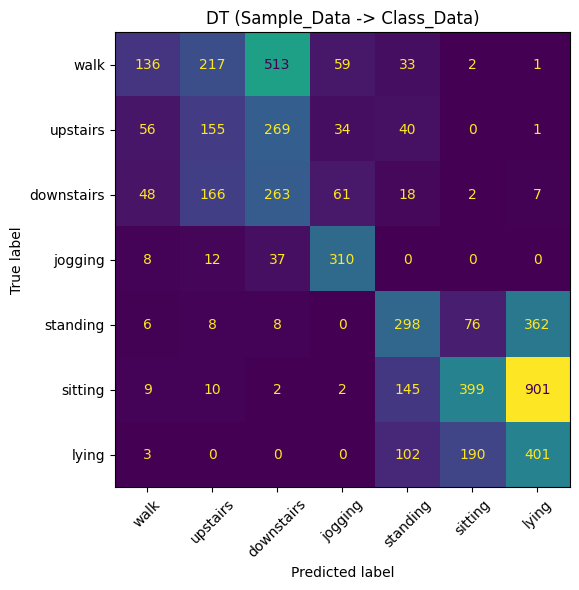

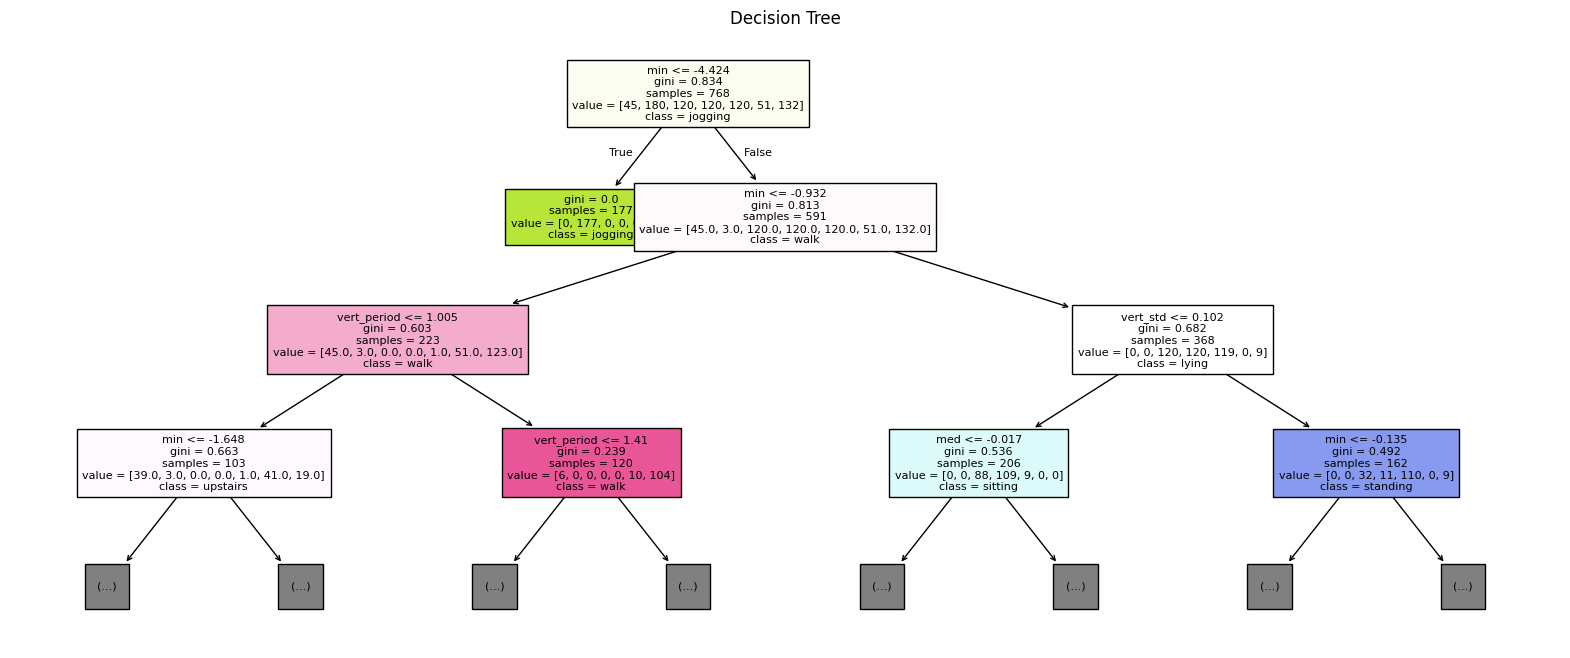

In [11]:
# Hints, step by step:
# Combine all the data under data/Sample_Data
# Combine all the data under data/Class_Data
# Train the decision tree
# Grid search, choosing by the Sample_Data test split accuracy
# Display the confusion matrix
# Visualize the tree
# Evaluate the model on class dataset

########################### TODO ##########################
sample_frames = all_data_to_combined_csv('./data/Sample_Data', f'sample_{WINDOW_SEC}s.csv', window_sec=WINDOW_SEC)
class_frames5 = all_data_to_combined_csv('./data/Class_Data', f'class_{WINDOW_SEC}s.csv', window_sec=WINDOW_SEC)
print(len(sample_frames), 'sample windows,', len(class_frames5), 'class windows')

DEPTHS = [2, 3, 4, 5, 6, 8, 10, 12, 15, None]
CRITERIA = ['gini', 'entropy']

def quiet(fn, *args, **kwargs):
    """Run a helper that prints a classification report without the printout."""
    import io, contextlib
    with contextlib.redirect_stdout(io.StringIO()):
        return fn(*args, **kwargs)

def grid_search_tree(frames):
    rows = []
    for criterion in CRITERIA:
        for depth in DEPTHS:
            _, _, acc = quiet(train_decision_tree, frames, max_depth=depth, criterion=criterion, features=FEATURES)
            rows.append({'criterion': criterion, 'max_depth': depth, 'split_acc': acc})
    grid = pd.DataFrame(rows)
    # highest split accuracy; ties go to the shallower tree
    grid['_depth'] = grid['max_depth'].fillna(1000)
    best = grid.sort_values(['split_acc', '_depth'], ascending=[False, True]).iloc[0]
    return grid.drop(columns='_depth'), {'criterion': best['criterion'],
                                          'max_depth': None if pd.isna(best['max_depth']) else int(best['max_depth'])}

def show_cm(y_true, y_pred, title, fname):
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(title)
    plt.tight_layout(); plt.savefig(f'figures/{fname}', dpi=150); plt.show()
    return cm

print('===== Default tree (max_depth=5, entropy), trained on Sample_Data =====')
dt1_default, _, acc1_default_split = train_decision_tree(sample_frames, features=FEATURES)
print('--- evaluated on Class_Data ---')
acc1_default_class, _ = evaluate(dt1_default, class_frames5)

grid1, best1 = grid_search_tree(sample_frames)
print(grid1.pivot(index='max_depth', columns='criterion', values='split_acc').round(3))
print('best hyperparameters (by Sample_Data split):', best1)

print('===== Best tree, trained on Sample_Data =====')
dt1_best, _, acc1_best_split = train_decision_tree(sample_frames, features=FEATURES, **best1)
print('--- evaluated on Class_Data ---')
acc1_best_class, pred1 = evaluate(dt1_best, class_frames5)
cm1 = show_cm(class_frames5['activity'], pred1, 'DT (Sample_Data -> Class_Data)', 'cm_c1_dt_sample_to_class.png')
viz_tree(dt1_best, class_frames5[FEATURES], list(dt1_best.classes_))
plt.savefig('figures/tree_c1.png', dpi=120); plt.show()

RESULTS['c1'] = {'default': {'split': acc1_default_split, 'test': acc1_default_class},
                 'best_params': best1, 'best': {'split': acc1_best_split, 'test': acc1_best_class},
                 'grid': grid1.to_dict('records')}


**For the data in the dataset:**

| Hyperparameters | Accuracy (Sample_Data test split) | Accuracy (Class_Data) |
|-|-|-|
| Default (max_depth=5, criterion='entropy') | 76.1% | 38.7% |
| max_depth=10, criterion='gini' | 84.8% | 36.5% |


#### 🛑 Interpretation of the results

**Write Below:**

**What the scores say.** The tree does well on the held-out 30% of Sample_Data (76.1% default, 84.8% tuned) but only 38.7% / 36.5% on the class corpus. The split score is optimistic: Sample_Data is 35 recordings of 3-5 min from 5 people, so windows of the same recording and person sit on both sides of the split. Class_Data is a new device (phone vs wrist), new placements and about 100 new people. Wrist and pocket differ physically: the wrist device's noise floor at rest is about 3x higher, and wrist walking is gentler. And the axis features mean something different on a wrist than in a pocket, so a tree that splits on `mean_z` or `var_frac_y` learns wrist-specific rules. With the first-round magnitude-only features the same tree transferred at 45.6%. The orientation features help on phones and hurt in this one direction.

**Which activities are distinguishable.** Jogging transfers (F1 0.74): it is 3-4x more intense than anything else on any device. Everything else is between 0.22 and 0.43 F1: walk 0.22, upstairs 0.28, downstairs 0.32, standing 0.43, sitting 0.37, lying 0.34.

**Hyperparameter tuning.** The grid prefers a deeper tree (max_depth=10, criterion='gini': split 76.1% → 84.8%), but the class-corpus accuracy *drops* 2.2 points. Tuning on a leaky split of five people fits those five people better and generalises worse. Five subjects are too few to learn a 7-class model that transfers.


## Assignment-Classification2: Testing Decision Tree Classifier Performance (Train: Class_Data, Test: Sample_Data)

In this section, you will do a grid search for hyperparameter tuning using class dataset. When you found the best model, you will evaluate it on the sample data. Check the instruction below for this section:

1. **Grid Search**: This time only use the class corpus for tuning the hyperparameters using grid search (max_depth and criterion in `train_decision_tree`). Basically train and evaluate models with different hyperparameters only using the class dataset and see what hyperparameters results in better performance on test split of class dataset (`train_decision_tree` returns it). Finally evaluate the best model on the sample dataset. 


2. **Performance Visualization**: To provide a visual understanding of the model's performance, we display the confusion matrix using matplotlib's `ConfusionMatrixDisplay` function. Each row of the matrix corresponds to a true class, while each column corresponds to a predicted class. The diagonal elements represent correctly classified instances, and off-diagonal elements are instances that are misclassified. Visualize the confusion matrix for the test set.

3. **Decision Tree Visualization**: Finally, visualize the decision tree using the `viz_tree` function (loaded from util.py). This function generates a graphic representation of the decision tree model, showing how it makes decisions based on the features.

4. **Fill up** this table based on the results you obtain by trying different parameters (fill both rows). We will evaluate the accuracy of numbers you fill up below.

5. **Interpretation of the results**: What do these accuracy scores suggest about the ability of the model to distinguish between these activities? Do some activities appear to be more distinguishable than others? what did you learn from hyperparameter tuning? Remember to provide a brief discussion for each point.

===== Default tree (max_depth=5, entropy), trained on Class_Data =====
              precision    recall  f1-score   support

  downstairs       0.82      0.17      0.28       193
     jogging       0.96      0.88      0.92       114
       lying       0.55      0.22      0.32       215
     sitting       0.67      0.76      0.71       420
    standing       0.46      0.66      0.54       196
    upstairs       0.32      0.48      0.39       162
        walk       0.56      0.70      0.62       311

    accuracy                           0.57      1611
   macro avg       0.62      0.55      0.54      1611
weighted avg       0.61      0.57      0.55      1611

Accuracy on test set: 0.5729360645561763
--- evaluated on Sample_Data ---
              precision    recall  f1-score   support

  downstairs       0.76      0.41      0.53        69
     jogging       0.95      0.97      0.96       253
       lying       0.27      0.03      0.06       179
     sitting       0.51      0.94      0.

criterion  entropy   gini
max_depth                
NaN          0.640  0.639
2.0          0.496  0.486
3.0          0.550  0.540
4.0          0.562  0.549
5.0          0.573  0.598
6.0          0.601  0.611
8.0          0.608  0.621
10.0         0.625  0.640
12.0         0.634  0.634
15.0         0.642  0.639
best hyperparameters (by Class_Data split): {'criterion': 'entropy', 'max_depth': 15}
===== Best tree, trained on Class_Data =====
              precision    recall  f1-score   support

  downstairs       0.56      0.53      0.55       193
     jogging       0.94      0.89      0.91       114
       lying       0.60      0.54      0.57       215
     sitting       0.76      0.73      0.74       420
    standing       0.48      0.57      0.52       196
    upstairs       0.41      0.52      0.46       162
        walk       0.75      0.68      0.71       311

    accuracy                           0.64      1611
   macro avg       0.64      0.64      0.64      1611
weighted avg   

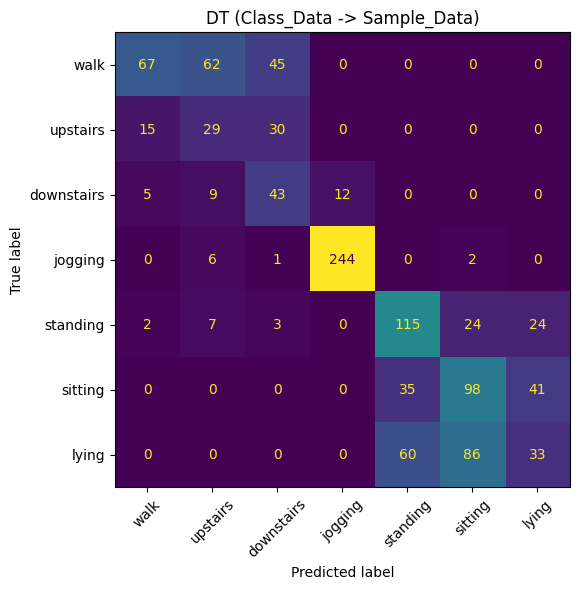

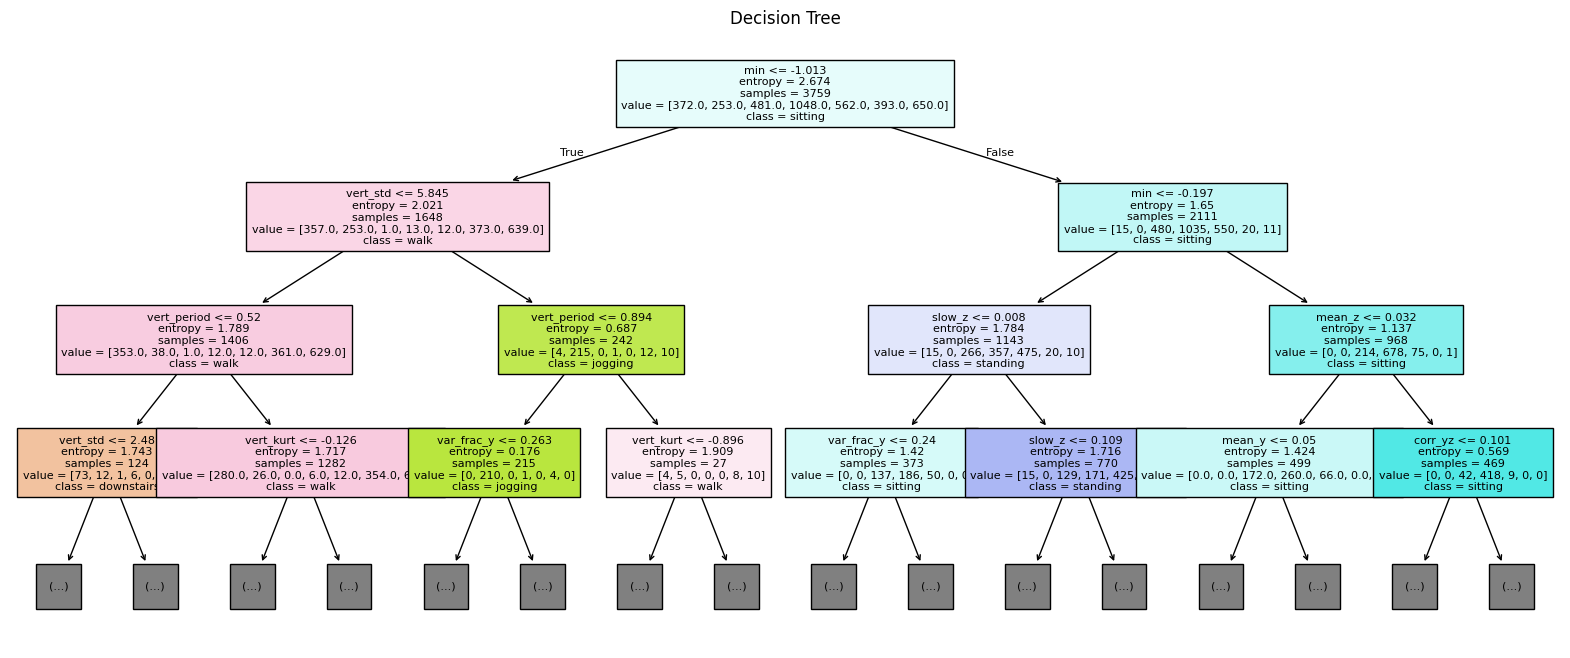

In [12]:
# roughly similar flow as previous section

########################### TODO ##########################
print('===== Default tree (max_depth=5, entropy), trained on Class_Data =====')
dt2_default, _, acc2_default_split = train_decision_tree(class_frames5, features=FEATURES)
print('--- evaluated on Sample_Data ---')
acc2_default_sample, _ = evaluate(dt2_default, sample_frames)

grid2, best2 = grid_search_tree(class_frames5)
print(grid2.pivot(index='max_depth', columns='criterion', values='split_acc').round(3))
print('best hyperparameters (by Class_Data split):', best2)

print('===== Best tree, trained on Class_Data =====')
dt2_best, cm2_split, acc2_best_split = train_decision_tree(class_frames5, features=FEATURES, **best2)
print('--- evaluated on Sample_Data ---')
acc2_best_sample, pred2 = evaluate(dt2_best, sample_frames)
cm2 = show_cm(sample_frames['activity'], pred2, 'DT (Class_Data -> Sample_Data)', 'cm_c2_dt_class_to_sample.png')
viz_tree(dt2_best, class_frames5[FEATURES], list(dt2_best.classes_))
plt.savefig('figures/tree_c2.png', dpi=120); plt.show()

RESULTS['c2'] = {'default': {'split': acc2_default_split, 'test': acc2_default_sample},
                 'best_params': best2, 'best': {'split': acc2_best_split, 'test': acc2_best_sample},
                 'grid': grid2.to_dict('records')}


**For the data in the dataset:**

| Hyperparameters | Accuracy (Class_Data test split) | Accuracy (Sample_Data) |
|-|-|-|
| Default (max_depth=5, criterion='entropy') | 57.3% | 63.4% |
| max_depth=15, criterion='entropy' | 64.2% | 57.3% |


#### 🛑 Interpretation of the results

**Write Below:**

**What the scores say.** Trained on the class corpus, the tree reaches 57.3% (default) / 64.2% (tuned) on its own split and 63.4% / 57.3% on Sample_Data. Transfer is much better than in the other direction: 612 recordings from many phones, placements and people cover far more variation than 35 recordings from 5 wrists. The in-domain split is low for a single tree because Class_Data is noisy: recordings range from 4 s to 27 min, phones sit in pockets, hands or on tables, and some labels are loose (a "walk" file named "cooking").

**Which activities are distinguishable.** On Sample_Data, jogging is nearly perfect (F1 0.96). Standing (0.60), sitting (0.51), walk (0.51) and downstairs (0.45) are partly right. Upstairs (0.31) and lying (0.24) are worst.

**Hyperparameter tuning.** The split picks max_depth=15, criterion='entropy' (+6.9 points on the split), yet Sample_Data accuracy *drops* from 63.4% to 57.3%. The random split leaks windows of the same recording into the test set, so it rewards deep trees that memorise recordings. A grouped CV agrees with the transfer result: depth 5 gets 52.4% vs 50.2% for depth 15 (Model Exploration cell). Lesson: tune on a split that holds out whole recordings, or people.


## Assignment-Classification3: Testing a new Classifier Performance (Train: Sample_Data, Test: Class_Data)

Repeat section Assignment-Classification1 with a different classifier, using the same window length and feature set. It could be Random Forest, kNN, Logistic regression, or any other classifier of your choice (add its import to the imports block). Tune its key hyperparameters the same way as in Classification1. Finally compare it with the decision tree in the assignment-classification1 section (model exploration, exploration report §2).

Note: kNN, Logistic Regression, and SVM are sensitive to feature scale, so standardize the features first (e.g., `make_pipeline(StandardScaler(), KNeighborsClassifier())`).

    n_estimators max_features  min_samples_leaf  max_depth  split_acc
0            200         sqrt                 1       20.0      0.900
1            200         sqrt                 1        NaN      0.897
2            200         sqrt                 2       20.0      0.897
3            200         sqrt                 2        NaN      0.897
4            200         sqrt                 5       20.0      0.858
5            200         sqrt                 5        NaN      0.858
6            200          0.5                 1       20.0      0.891
7            200          0.5                 1        NaN      0.894
8            200          0.5                 2       20.0      0.885
9            200          0.5                 2        NaN      0.888
10           200          0.5                 5       20.0      0.870
11           200          0.5                 5        NaN      0.870
12           500         sqrt                 1       20.0      0.894
13           500    

              precision    recall  f1-score   support

  downstairs       0.43      0.28      0.34       565
     jogging       0.76      0.86      0.81       367
       lying       0.27      0.43      0.33       696
     sitting       0.70      0.40      0.51      1468
    standing       0.40      0.61      0.48       758
    upstairs       0.34      0.19      0.25       555
        walk       0.54      0.66      0.59       961

    accuracy                           0.48      5370
   macro avg       0.49      0.49      0.47      5370
weighted avg       0.51      0.48      0.47      5370

Accuracy on test set: 0.4759776536312849


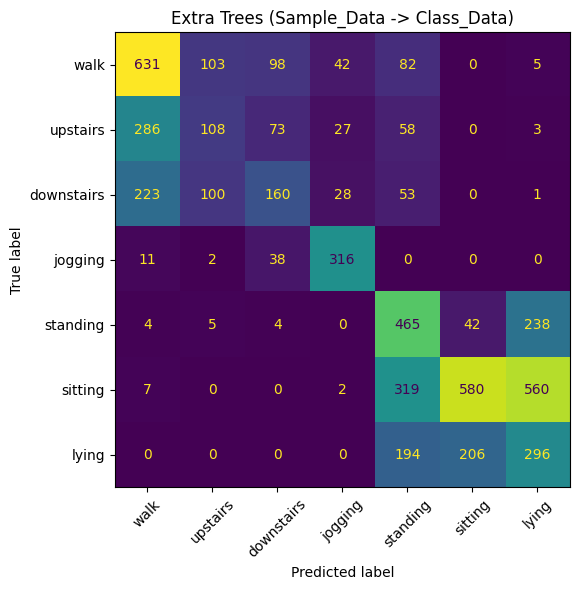

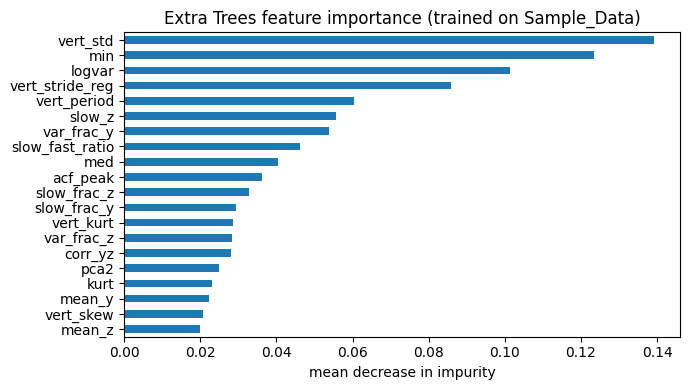

            DT F1  ET F1   gain
walk        0.222  0.594  0.373
upstairs    0.276  0.247 -0.029
downstairs  0.317  0.341  0.024
jogging     0.744  0.808  0.064
standing    0.428  0.482  0.055
sitting     0.373  0.505  0.132
lying       0.339  0.329 -0.009


In [13]:
# Hints, step by step:
# Write a code for evaluation and training the new classifier
# Train the new classifier
# Display the confusion matrix
# Visualize the model if it makes sense (a tree, or feature importances for a forest)
# Evaluate the model on class dataset

########################### TODO ##########################
def train_model(frames, model, features=None, verbose=True):
    """train_decision_tree for any sklearn classifier: same 70/30 split (random_state=42)."""
    if features is None:
        features = feature_columns(frames)
    X_train, X_test, y_train, y_test = train_test_split(frames[list(features)], frames['activity'],
                                                        test_size=0.3, random_state=42)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    if verbose:
        print(classification_report(y_test, pred, zero_division=0))
        print("Accuracy on test set:", acc)
    return model, confusion_matrix(y_test, pred, labels=model.classes_), acc

# Extra Trees = a random forest that also draws the split thresholds at random, which averages out
# more of the person-to-person noise (it beat the random forest with recordings held out, Model Exploration).
ET_GRID = [{'n_estimators': n, 'max_features': mf, 'min_samples_leaf': leaf, 'max_depth': d}
           for n in [200, 500] for mf in ['sqrt', 0.5] for leaf in [1, 2, 5] for d in [20, None]]

def make_et(p):
    return ExtraTreesClassifier(random_state=42, n_jobs=-1, **p)

def grid_search_et(frames):
    rows = []
    for p in ET_GRID:
        _, _, acc = train_model(frames, make_et(p), FEATURES, verbose=False)
        rows.append({**p, 'split_acc': acc})
    grid = pd.DataFrame(rows)
    # highest split accuracy; ties go to fewer trees / larger leaves
    best = grid.sort_values(['split_acc', 'n_estimators', 'min_samples_leaf'], ascending=[False, True, False]).iloc[0]
    params = {'n_estimators': int(best['n_estimators']),
              'max_features': best['max_features'] if isinstance(best['max_features'], str) else float(best['max_features']),
              'min_samples_leaf': int(best['min_samples_leaf']),
              'max_depth': None if pd.isna(best['max_depth']) else int(best['max_depth'])}
    return grid, params

def plot_importances(model, title, fname):
    imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
    imp.plot.barh(figsize=(7, 4), title=title)
    plt.xlabel('mean decrease in impurity'); plt.tight_layout(); plt.savefig(f'figures/{fname}', dpi=150); plt.show()
    return imp

grid3, best3 = grid_search_et(sample_frames)
print(grid3.round(3).to_string())
print('best hyperparameters (by Sample_Data split):', best3)

print('===== Best extra trees, trained on Sample_Data =====')
et3_best, _, acc3_best_split = train_model(sample_frames, make_et(best3), FEATURES)
print('--- evaluated on Class_Data ---')
acc3_best_class, pred3 = evaluate(et3_best, class_frames5)
cm3 = show_cm(class_frames5['activity'], pred3, 'Extra Trees (Sample_Data -> Class_Data)', 'cm_c3_et_sample_to_class.png')
imp3 = plot_importances(et3_best, 'Extra Trees feature importance (trained on Sample_Data)', 'imp_c3.png')

f1_dt1 = f1_score(class_frames5['activity'], pred1, labels=CLASSES, average=None, zero_division=0)
f1_rf3 = f1_score(class_frames5['activity'], pred3, labels=CLASSES, average=None, zero_division=0)
print(pd.DataFrame({'DT F1': f1_dt1, 'ET F1': f1_rf3, 'gain': f1_rf3 - f1_dt1}, index=CLASSES).round(3))

RESULTS['c3'] = {'best_params': best3, 'best': {'split': acc3_best_split, 'test': acc3_best_class},
                 'f1_dt': dict(zip(CLASSES, f1_dt1)), 'f1_rf': dict(zip(CLASSES, f1_rf3))}


**For the data in the dataset:**

| Hyperparameters | Accuracy (Sample_Data test split) | Accuracy (Class_Data) |
|-|-|-|
| ExtraTrees(n_estimators=200, max_features='sqrt', min_samples_leaf=1, max_depth=20) | 90.0% | 47.6% |


#### 🛑 Interpretation of the results and comparison to the decision tree.

**Write Below:**

**Extra Trees vs decision tree (Sample_Data → Class_Data).** Extra Trees is a random forest that also picks its split thresholds at random. It beats the best tree on the Sample_Data split (90.0% vs 84.8%) and on the class corpus (47.6% vs 36.5%, +11.1 points). Averaging 200 randomised trees smooths out the thresholds a single tree overfits to five people, which matters most in this direction.

**Where the gain is.** Mostly walk (+0.37 F1) and sitting (+0.13), then jogging (+0.06) and standing (+0.05). Upstairs (-0.03), downstairs (+0.02) and lying (-0.01) do not improve: trained on 5 wrists, no model learns the subtle cues for those classes. The ~48% here is the ceiling of this direction, not a modelling problem.


## Assignment-Classification4: Testing a new Classifier Performance (Train: Class_Data, Test: Sample_Data)

Repeat section Assignment-Classification2 with your new classifier. Also, compare it with the decision tree in the assignment-classification2 section. Did the better model help all classes equally, or did the gain concentrate on specific classes?

    n_estimators max_features  min_samples_leaf  max_depth  split_acc
0            200         sqrt                 1       20.0      0.752
1            200         sqrt                 1        NaN      0.762
2            200         sqrt                 2       20.0      0.734
3            200         sqrt                 2        NaN      0.737
4            200         sqrt                 5       20.0      0.684
5            200         sqrt                 5        NaN      0.689
6            200          0.5                 1       20.0      0.780
7            200          0.5                 1        NaN      0.772
8            200          0.5                 2       20.0      0.767
9            200          0.5                 2        NaN      0.758
10           200          0.5                 5       20.0      0.726
11           200          0.5                 5        NaN      0.723
12           500         sqrt                 1       20.0      0.760
13           500    

              precision    recall  f1-score   support

  downstairs       0.82      0.73      0.77       193
     jogging       0.98      0.98      0.98       114
       lying       0.91      0.47      0.62       215
     sitting       0.76      0.91      0.83       420
    standing       0.64      0.74      0.68       196
    upstairs       0.75      0.65      0.70       162
        walk       0.79      0.87      0.83       311

    accuracy                           0.78      1611
   macro avg       0.81      0.76      0.77      1611
weighted avg       0.79      0.78      0.77      1611

Accuracy on test set: 0.7802607076350093
--- evaluated on Sample_Data ---
              precision    recall  f1-score   support

  downstairs       0.51      0.78      0.62        69
     jogging       0.98      0.98      0.98       253
       lying       0.33      0.02      0.03       179
     sitting       0.55      0.90      0.68       174
    standing       0.66      0.85      0.74       175
    

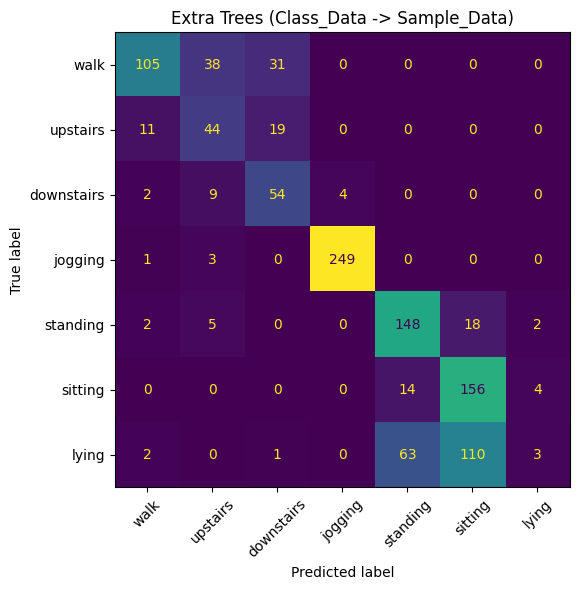

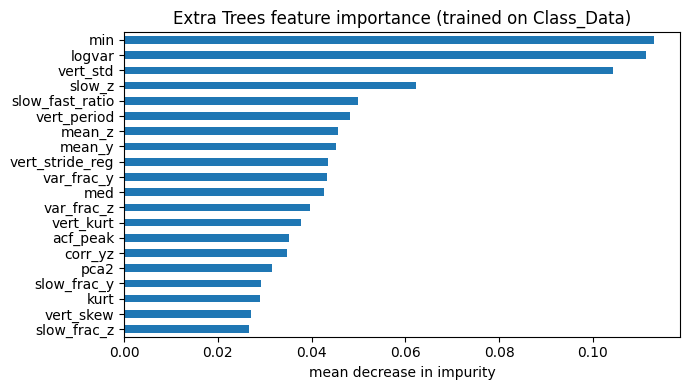

            DT F1  ET F1   gain
walk        0.510  0.707  0.198
upstairs    0.310  0.509  0.199
downstairs  0.450  0.621  0.170
jogging     0.959  0.984  0.025
standing    0.597  0.740  0.143
sitting     0.510  0.681  0.171
lying       0.238  0.032 -0.206


In [14]:
# roughly similar flow as previous section

########################### TODO ##########################
grid4, best4 = grid_search_et(class_frames5)
print(grid4.round(3).to_string())
print('best hyperparameters (by Class_Data split):', best4)

print('===== Best extra trees, trained on Class_Data =====')
et4_best, _, acc4_best_split = train_model(class_frames5, make_et(best4), FEATURES)
print('--- evaluated on Sample_Data ---')
acc4_best_sample, pred4 = evaluate(et4_best, sample_frames)
cm4 = show_cm(sample_frames['activity'], pred4, 'Extra Trees (Class_Data -> Sample_Data)', 'cm_c4_et_class_to_sample.png')
imp4 = plot_importances(et4_best, 'Extra Trees feature importance (trained on Class_Data)', 'imp_c4.png')

f1_dt2 = f1_score(sample_frames['activity'], pred2, labels=CLASSES, average=None, zero_division=0)
f1_rf4 = f1_score(sample_frames['activity'], pred4, labels=CLASSES, average=None, zero_division=0)
print(pd.DataFrame({'DT F1': f1_dt2, 'ET F1': f1_rf4, 'gain': f1_rf4 - f1_dt2}, index=CLASSES).round(3))

RESULTS['c4'] = {'best_params': best4, 'best': {'split': acc4_best_split, 'test': acc4_best_sample},
                 'f1_dt': dict(zip(CLASSES, f1_dt2)), 'f1_rf': dict(zip(CLASSES, f1_rf4)),
                 'importance': imp4.to_dict()}


**For the data in the dataset:**

| Hyperparameters | Accuracy (Class_Data test split) | Accuracy (Sample_Data) |
|-|-|-|
| ExtraTrees(n_estimators=200, max_features=0.5, min_samples_leaf=1, max_depth=20) | 78.0% | 69.1% |


#### 🛑 Interpretation of the results and comparison to the decision tree.

**Write Below:**

**Extra Trees vs decision tree (Class_Data → Sample_Data).** Extra Trees wins clearly: 78.0% vs 64.2% on the class split and **69.1%** vs 57.3% on Sample_Data (+11.8 points). Its most important features are `min` (0.11), `logvar` (0.11) and `vert_std` (0.10): overall intensity first, then the slow-drift and vertical-proxy features.

**Did it help all classes equally? No.** The gain is spread over five classes: walk 0.51→0.71, upstairs 0.31→0.51, downstairs 0.45→0.62, standing 0.60→0.74, sitting 0.51→0.68. Jogging was already solved (0.98). Lying gets **worse** (0.24→0.03). The ensemble votes a still wrist into "sitting" or "standing", most likely because in the class corpus a still phone is more often a sitting recording than a lying one. That gap is in the data (no posture signal), not in the model.


## Model Exploration: same features, nine classifiers (exploration report §2)

Every model uses the locked 5 s windows and `FEATURES`. The notebook split puts windows from the same recording on both sides of the split, so it overstates accuracy; the grouped CV holds out whole recordings and is the number we trust for choosing a model.

In [15]:
#### Model exploration (exploration report §2)
# Same FEATURES, same 5 s windows. Three numbers per model:
#   split      : the notebook's 70/30 window split of Class_Data (windows of one recording land on both sides)
#   grouped CV : 5-fold CV on Class_Data with whole recordings held out (what a new user would see)
#   C->S, S->C : train on one corpus, test on the other
MODELS = {
    'Decision Tree (entropy, depth 5)': lambda: DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=42),
    f'Decision Tree ({best2["criterion"]}, depth {best2["max_depth"]})': lambda: DecisionTreeClassifier(random_state=42, **best2),
    'Random Forest (300 trees)': lambda: RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    f'Extra Trees {best4}': lambda: make_et(best4),
    'HistGradientBoosting (lr 0.05, 300 it)': lambda: HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=42),
    'Gradient Boosting (100, depth 3)': lambda: GradientBoostingClassifier(random_state=42),
    'kNN (k=15, scaled)': lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    'Logistic Regression (C=1, scaled)': lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000)),
    'SVM (RBF, C=3, scaled)': lambda: make_pipeline(StandardScaler(), SVC(C=3, random_state=42)),
}
model_rows = []
for name, make in MODELS.items():
    _, _, split_acc = train_model(class_frames5, make(), FEATURES, verbose=False)
    cv_acc, cv_pred = grouped_cv(class_frames5, FEATURES, make)
    c2s = accuracy_score(sample_frames['activity'], make().fit(class_frames5[FEATURES], class_frames5['activity']).predict(sample_frames[FEATURES]))
    s2c = accuracy_score(class_frames5['activity'], make().fit(sample_frames[FEATURES], sample_frames['activity']).predict(class_frames5[FEATURES]))
    f1 = f1_score(class_frames5['activity'], cv_pred, labels=CLASSES, average=None, zero_division=0)
    model_rows.append({'model': name, 'split': split_acc, 'grouped_cv': cv_acc, 'C->S': c2s, 'S->C': s2c,
                       **{f'f1_{c}': v for c, v in zip(CLASSES, f1)}})
model_table = pd.DataFrame(model_rows)
print(model_table.round(3).to_string())
RESULTS['models'] = model_rows


                                                                                            model  split  grouped_cv   C->S   S->C  f1_walk  f1_upstairs  f1_downstairs  f1_jogging  f1_standing  f1_sitting  f1_lying
0                                                                Decision Tree (entropy, depth 5)  0.573       0.524  0.613  0.470    0.597        0.071          0.304       0.812        0.546       0.660     0.210
1                                                               Decision Tree (entropy, depth 15)  0.642       0.502  0.566  0.393    0.607        0.332          0.461       0.832        0.474       0.555     0.305
2                                                                       Random Forest (300 trees)  0.749       0.647  0.671  0.484    0.745        0.438          0.604       0.921        0.637       0.711     0.342
3  Extra Trees {'n_estimators': 200, 'max_features': 0.5, 'min_samples_leaf': 1, 'max_depth': 20}  0.780       0.657  0.668  0.477    0.760 

###  Assignment: Function 4: predict_recordings(model, frames, features)

So far every number is a **window** accuracy. A real app labels a whole recording, so aggregate the window predictions of each recording into one label (exploration report §3).

**Hints and Instructions:**
- The function takes as arguments:
  - `model`: a trained classifier
  - `frames`: a feature DataFrame with the `activity` and `recording` columns
  - `features`: the feature columns the model was trained on
- The function will perform the following:
  - Predict the label of every window
  - Group the predictions by `recording` and take the most common label (majority vote). You may also try confidence-weighting with `model.predict_proba`.
  - Return a DataFrame with one row per recording and the columns `true` and `predicted`

In [16]:
def predict_recordings(model, frames, features=None):
    # By default, use the same columns the model was trained on
    if features is None:
        features = getattr(model, 'feature_names_in_', feature_columns(frames))

    ######## TODO ###############
    # Sample_Data reuses file names (026.csv ...) in every activity folder, so a recording is
    # identified by (activity folder, file name), not by the file name alone.
    pred = model.predict(frames[list(features)])
    proba = model.predict_proba(frames[list(features)]) if hasattr(model, 'predict_proba') else None
    keys = ['activity', 'recording'] if 'activity' in frames.columns else ['recording']
    rows = []
    for key, idx in frames.groupby(keys).indices.items():
        votes = pd.Series(pred[idx]).value_counts()
        tied = list(votes.index[votes == votes.max()])
        if len(tied) > 1 and proba is not None:
            # majority vote; a tie goes to the tied label with the highest summed probability
            summed = dict(zip(model.classes_, proba[idx].sum(axis=0)))
            label = max(tied, key=lambda c: summed[c])
        else:
            label = tied[0]
        key = key if isinstance(key, tuple) else (key,)
        rows.append({'recording': key[-1], 'true': frames['activity'].iloc[idx[0]] if 'activity' in frames.columns else None,
                     'predicted': label, 'windows': len(idx)})
    recordings = pd.DataFrame(rows)
    #############################

    return recordings


## Assignment-Classification5: Recording-Level Predictions

Use `predict_recordings` with your best decision tree and your best new classifier from Classification2 and Classification4 (trained on Class_Data), on Sample_Data. Then do the same for your models from Classification1 and Classification3 (trained on Sample_Data), on Class_Data.

1. **Fill up** this table.

2. **Interpretation of the results**: Does aggregating help? For which classes? When can majority vote make things worse?

Decision Tree (best)   Class_Data -> Sample_Data: window 0.573  recording 0.686  (35 recordings)
               downstairs  jogging  lying  sitting  standing  upstairs   walk
window acc          0.623    0.964  0.184    0.563     0.657     0.392  0.385
recording acc       0.800    1.000  0.000    1.000     1.000     0.400  0.600 



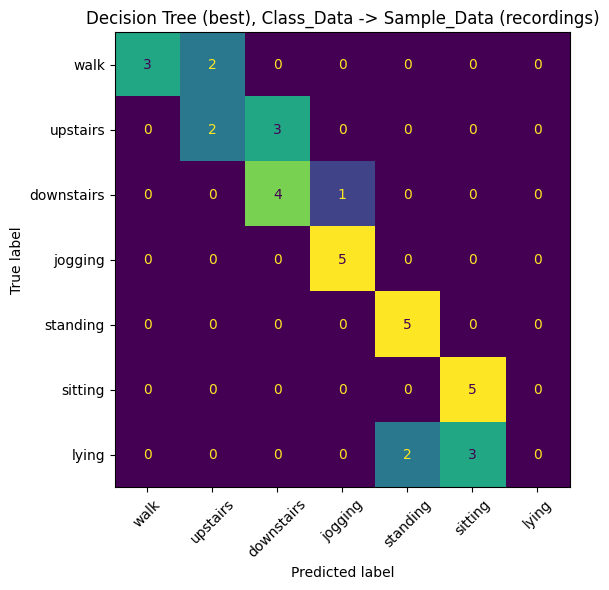

Extra Trees (best)     Class_Data -> Sample_Data: window 0.691  recording 0.743  (35 recordings)
               downstairs  jogging  lying  sitting  standing  upstairs   walk
window acc          0.783    0.984  0.017    0.897     0.846     0.595  0.603
recording acc       1.000    1.000  0.000    1.000     1.000     0.600  0.600 



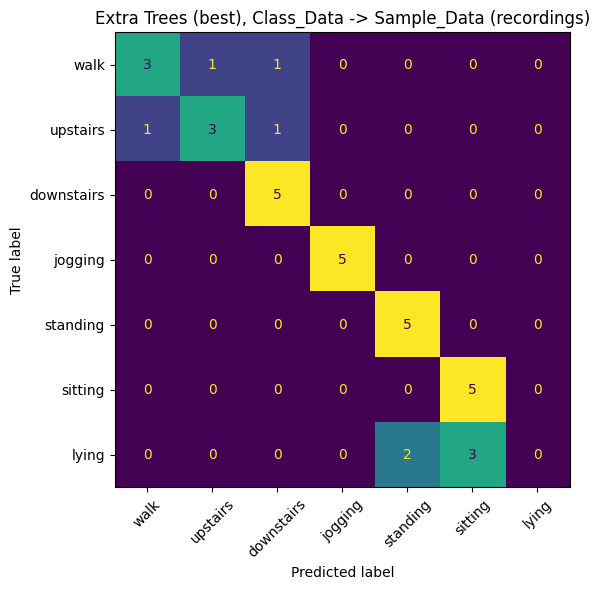

Decision Tree (best)   Sample_Data -> Class_Data: window 0.365  recording 0.376  (612 recordings)
               downstairs  jogging  lying  sitting  standing  upstairs   walk
window acc          0.465    0.845  0.576    0.272     0.393     0.279  0.142
recording acc       0.500    0.769  0.695    0.233     0.402     0.289  0.098 



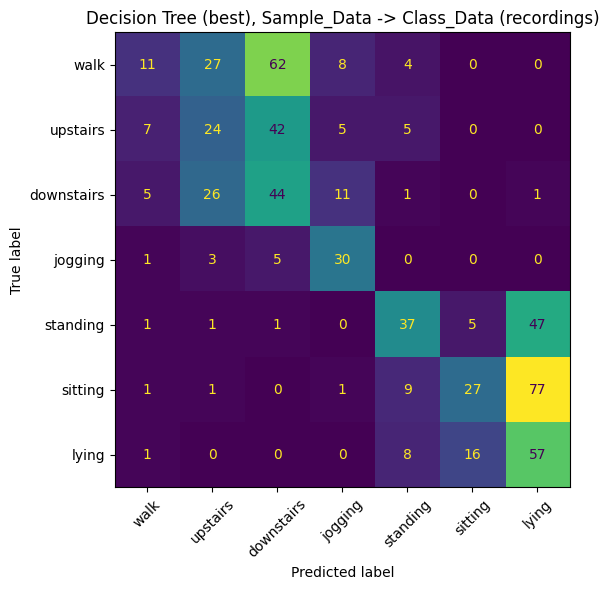

Extra Trees (best)     Sample_Data -> Class_Data: window 0.476  recording 0.495  (612 recordings)
               downstairs  jogging  lying  sitting  standing  upstairs   walk
window acc          0.283    0.861  0.425    0.395     0.613     0.195  0.657
recording acc       0.295    0.846  0.476    0.319     0.663     0.181  0.821 



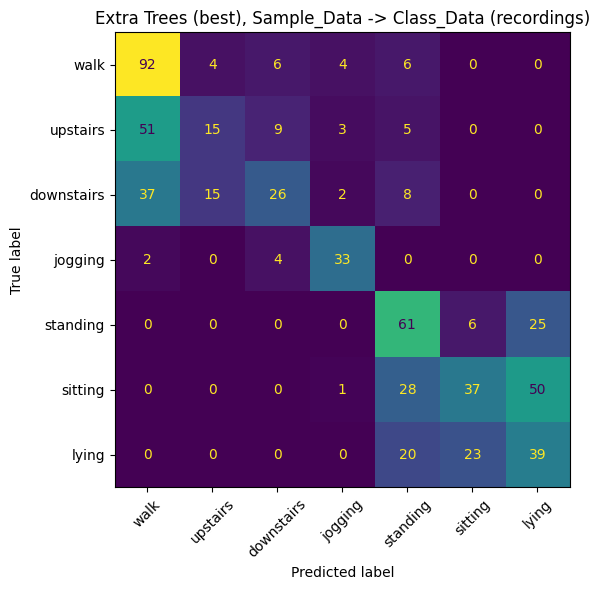

In [17]:
# Hints, step by step:
# Call predict_recordings for each model and test set
# Recording-level accuracy = (recordings['true'] == recordings['predicted']).mean()
# Display a confusion matrix of the recording-level predictions

########################### TODO ##########################
def confidence_vote(model, frames, features):
    """Alternative aggregation: sum predict_proba over the windows of a recording, take the argmax."""
    proba = pd.DataFrame(model.predict_proba(frames[features]), columns=model.classes_, index=frames.index)
    summed = proba.groupby([frames['activity'], frames['recording']]).sum()
    return (summed.idxmax(axis=1) == summed.index.get_level_values(0)).mean()

runs = [('Decision Tree (best)', dt2_best, 'Class_Data -> Sample_Data', sample_frames, acc2_best_sample),
        ('Extra Trees (best)', et4_best, 'Class_Data -> Sample_Data', sample_frames, acc4_best_sample),
        ('Decision Tree (best)', dt1_best, 'Sample_Data -> Class_Data', class_frames5, acc1_best_class),
        ('Extra Trees (best)', et3_best, 'Sample_Data -> Class_Data', class_frames5, acc3_best_class)]
rec_rows = []
for name, model, direction, test, win_acc in runs:
    recs = predict_recordings(model, test, FEATURES)
    rec_acc = (recs['true'] == recs['predicted']).mean()
    per_class = recs.assign(ok=recs['true'] == recs['predicted']).groupby('true')['ok'].mean()
    win_per_class = pd.Series(model.predict(test[FEATURES]) == test['activity'].values).groupby(test['activity'].values).mean()
    rec_rows.append({'model': name, 'direction': direction, 'window_acc': win_acc, 'recording_acc': rec_acc,
                     'confidence_vote_acc': confidence_vote(model, test, FEATURES), 'recordings': len(recs),
                     'per_class_window': win_per_class.to_dict(), 'per_class_recording': per_class.to_dict()})
    print(f'{name:22s} {direction}: window {win_acc:.3f}  recording {rec_acc:.3f}  ({len(recs)} recordings)')
    print(pd.DataFrame({'window acc': win_per_class, 'recording acc': per_class}).round(3).T.to_string(), '\n')
    show_cm(recs['true'], recs['predicted'], f'{name}, {direction} (recordings)',
            f"cm_rec_{name.split()[0].lower()}_{direction.split()[0].lower()}.png")
RESULTS['recordings'] = rec_rows


**For the data in the dataset:**

| Model | Train → Test | Window accuracy | Recording accuracy |
|-|-|-|-|
| Decision Tree (best) | Class_Data → Sample_Data | 57.3% | 68.6% |
| Extra Trees (best) | Class_Data → Sample_Data | 69.1% | **74.3%** |
| Decision Tree (best) | Sample_Data → Class_Data | 36.5% | 37.6% |
| Extra Trees (best) | Sample_Data → Class_Data | 47.6% | 49.5% |


#### 🛑 Interpretation of the results

**Write Below:**

**Does aggregating help?** Yes, for every model and direction: +11.3 points for the tree and +5.2 for Extra Trees on Sample_Data, and +1-2 points on Class_Data. A majority vote amplifies whatever the window classifier does on a recording. When most windows are right, stray errors are outvoted: for Extra Trees on Sample_Data, sitting goes 90% → 100% of recordings, standing 85% → 100%, downstairs 78% → 100%.

**When majority vote makes things worse.** (1) A class whose windows are right less than half the time: the vote turns a partial score into zero (lying: 2% of windows, 0% of recordings). (2) Short recordings: a 10 s recording has 1-2 windows, so one bad window decides it. (3) Window accuracy is dominated by a few very long recordings (one 27-minute sitting file alone gives 323 windows), while recording accuracy counts each recording once. (4) Recordings that mix activities, such as handling the phone at the start, can be outvoted toward the wrong label. We also tried confidence weighting (summing `predict_proba` over a recording): 71.4% vs 74.3% for Extra Trees and 65.7% vs 68.6% for the tree on Sample_Data. Majority vote won, so we kept it and use summed probability only to break ties.


## Assignment-Failure Analysis (for exploration report §4 and §5)

Pick your final pipeline (exploration report §3) and look at where it fails.

1. From its confusion matrix, find the **top 2 failure modes** (the largest off-diagonal cells, e.g., upstairs predicted as walk).
2. For each failure mode, use the `recording` column to find a recording or window where the failure is clear. Plot its trace (`filtered_accel_mag` over time) and compare its feature values to the typical (median) feature values of the correct class and of the predicted class.
3. Use these figures in §5 of your exploration report, and decide whether each failure is a **feature** problem or a **model** problem.

window accuracy (recordings held out): 0.657
                 pred walk  pred upstairs  pred downstairs  pred jogging  pred standing  pred sitting  pred lying
true walk              803             64               75             3             12             4           0
true upstairs          191            219              116             7             21             1           0
true downstairs        119            109              326             2              6             1           2
true jogging            15              1               12           339              0             0           0
true standing           11              4                4             0            498           198          43
true sitting            12              1                0             2            128          1169         156
true lying               0              0                1             0            111           410         174


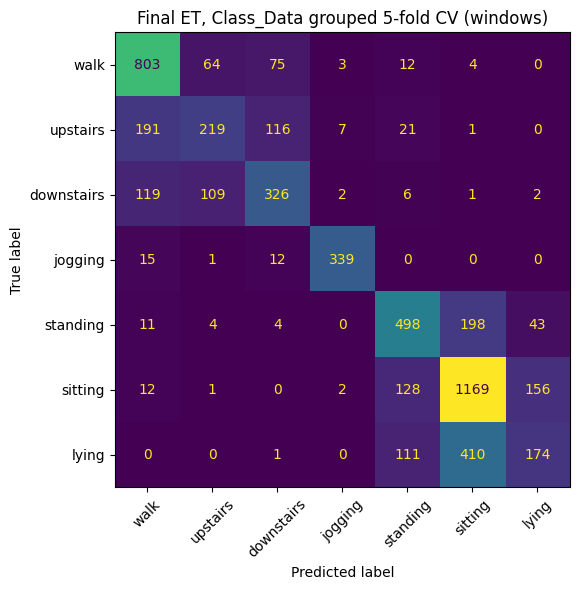

recording accuracy (majority vote, recordings held out):

 0.668


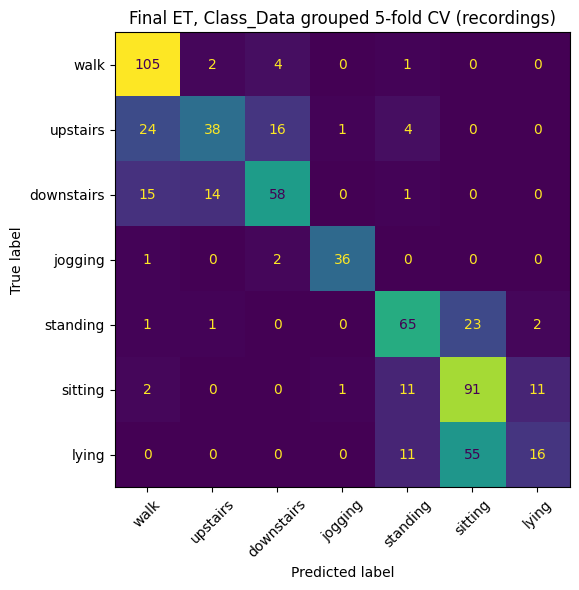

     lying predicted as sitting   : 410 windows (59% of lying)
  standing predicted as sitting   : 198 windows (26% of standing)
  upstairs predicted as walk      : 191 windows (34% of upstairs)
   sitting predicted as lying     : 156 windows (11% of sitting)
   sitting predicted as standing  : 128 windows (9% of sitting)
downstairs predicted as walk      : 119 windows (21% of downstairs)
              min  vert_period  vert_std  slow_fast_ratio  vert_stride_reg  slow_z  var_frac_y   kurt  mean_z  acf_peak  mean_y  var_frac_z  vert_kurt  logvar   pca2  vert_skew  slow_frac_y  slow_frac_z    med  corr_yz
activity                                                                                                                                                                                                                  
downstairs -2.675        0.831     3.012            0.720            0.360   0.554       0.355  0.399   0.008     0.362  -0.227       0.289     -0.243   1.120  0.266     

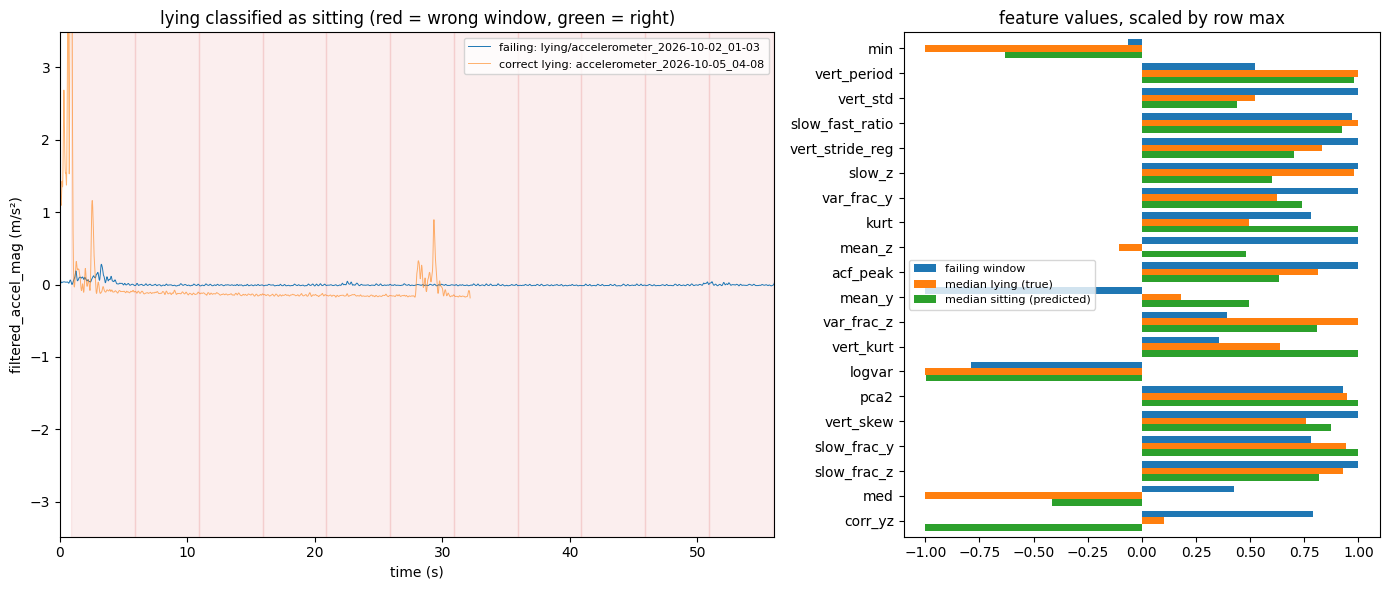

                 failing window  median lying (true)  median sitting (predicted)
min                      -0.015               -0.225                      -0.142
vert_period               0.352                0.673                       0.660
vert_std                  0.063                0.033                       0.028
slow_fast_ratio           0.232                0.239                       0.221
vert_stride_reg           0.219                0.182                       0.153
slow_z                    0.008                0.008                       0.005
var_frac_y                0.321                0.200                       0.237
kurt                      1.670                1.058                       2.132
mean_z                    0.028               -0.003                       0.014
acf_peak                  0.484                0.393                       0.306
mean_y                   -0.006                0.001                       0.003
var_frac_z                0.

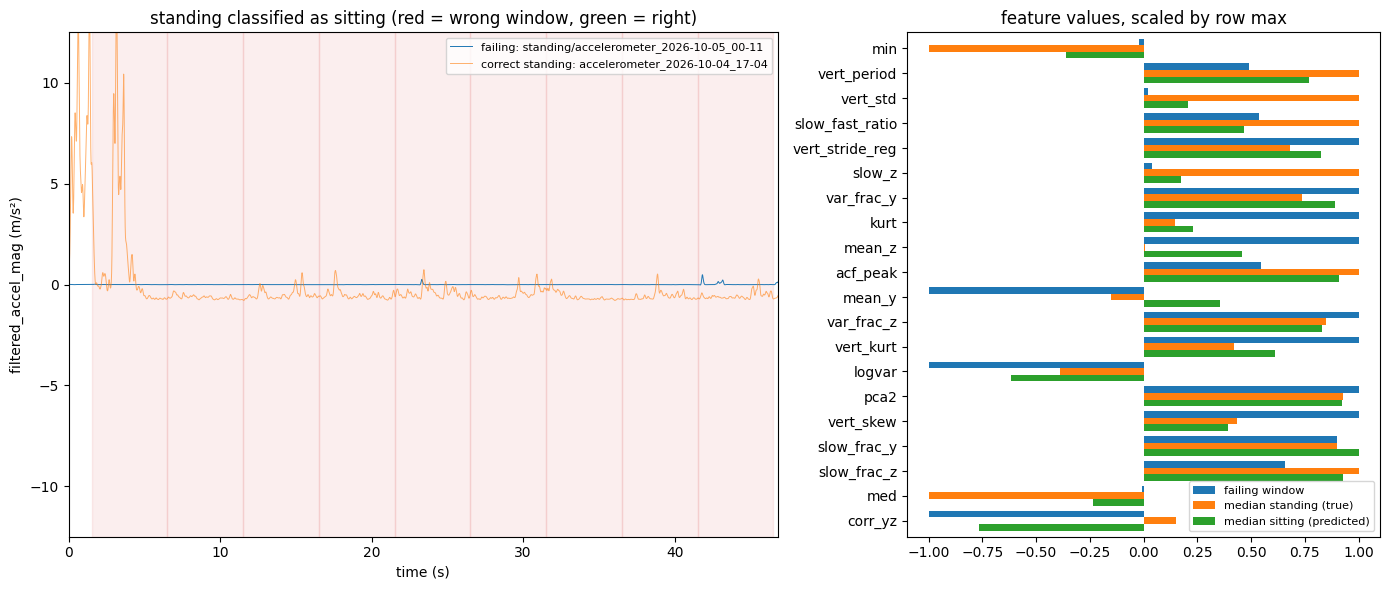

                 failing window  median standing (true)  median sitting (predicted)
min                      -0.008                  -0.391                      -0.142
vert_period               0.421                   0.858                       0.660
vert_std                  0.003                   0.134                       0.028
slow_fast_ratio           0.255                   0.472                       0.221
vert_stride_reg           0.186                   0.126                       0.153
slow_z                    0.001                   0.028                       0.005
var_frac_y                0.267                   0.196                       0.237
kurt                      9.200                   1.352                       2.132
mean_z                    0.030                   0.000                       0.014
acf_peak                  0.184                   0.337                       0.306
mean_y                   -0.008                  -0.001                     

In [18]:
# Hints, step by step:
# Find misclassified windows: frames[pred != frames['activity']]
# Pick one recording, reload its CSV, apply calc_magnitude and remove_noise, and plot filtered_accel_mag
# Compare: frames.groupby('activity')[FEATURES].median() vs the feature values of the failing window

########################### TODO ##########################
# Final pipeline (report §3): 5 s windows, FEATURES, random forest with the Class_Data-tuned hyperparameters,
# majority vote per recording. Its confusion matrix comes from 5-fold CV on Class_Data with whole recordings
# held out, so every window is predicted by a model that never saw its recording.
final_make = lambda: make_et(best4)
cv_acc, oof = grouped_cv(class_frames5, FEATURES, final_make)
frames = class_frames5.assign(pred=oof)
cm = confusion_matrix(frames['activity'], frames['pred'], labels=CLASSES)
cm_df = pd.DataFrame(cm, index=[f'true {c}' for c in CLASSES], columns=[f'pred {c}' for c in CLASSES])
print('window accuracy (recordings held out):', round(cv_acc, 3))
print(cm_df.to_string())
show_cm(frames['activity'], frames['pred'], 'Final ET, Class_Data grouped 5-fold CV (windows)', 'cm_final_windows.png')

rec = (frames.groupby(['activity', 'recording'])['pred'].agg(lambda s: s.value_counts().idxmax())
       .rename('predicted').reset_index().rename(columns={'activity': 'true'}))
rec_cv_acc = (rec['true'] == rec['predicted']).mean()
print('recording accuracy (majority vote, recordings held out):', round(rec_cv_acc, 3))
show_cm(rec['true'], rec['predicted'], 'Final ET, Class_Data grouped 5-fold CV (recordings)', 'cm_final_recordings.png')

# top-2 failure modes = largest off-diagonal cells
off = cm_df.copy().values.astype(float); np.fill_diagonal(off, 0)
order = np.dstack(np.unravel_index(np.argsort(-off.ravel()), off.shape))[0][:6]
top = [(CLASSES[i], CLASSES[j], int(cm[i, j]), cm[i, j] / cm[i].sum()) for i, j in order]
for t in top:
    print(f'{t[0]:>10s} predicted as {t[1]:<10s}: {t[2]} windows ({t[3]:.0%} of {t[0]})')

medians = frames.groupby('activity')[FEATURES].median()
print(medians.round(3).to_string())

def show_failure(true_c, pred_c, k):
    # recording with the most windows of this confusion (at least 5 windows, mostly wrong)
    bad = frames[(frames['activity'] == true_c)]
    stats = bad.groupby('recording')['pred'].agg(n='size', hits=lambda s: (s == pred_c).sum())
    stats = stats[stats['n'] >= 5]
    stats['frac'] = stats['hits'] / stats['n']
    rec_name = stats.sort_values(['frac', 'n'], ascending=False).index[0]
    win = bad[(bad['recording'] == rec_name) & (bad['pred'] == pred_c)].iloc[0]
    print(f'\nFailure {k}: {true_c} -> {pred_c}, recording {true_c}/{rec_name}: '
          f'{int(stats.loc[rec_name, "hits"])}/{int(stats.loc[rec_name, "n"])} windows predicted {pred_c}')

    raw = pd.read_csv(f'./data/Class_Data/{true_c}/{rec_name}', parse_dates=['time'])[['time', 'x', 'y', 'z']]
    dt = raw['time'].diff().dt.total_seconds()
    fs = 1 / dt[dt > 0].median()
    raw = remove_noise(calc_magnitude(raw), fs)
    t = (raw['time'] - raw['time'].iloc[0]).dt.total_seconds()

    # a typical correctly classified recording of the true class, for comparison
    good = frames[(frames['activity'] == true_c)].groupby('recording')['pred'].agg(n='size', ok=lambda s: (s == true_c).mean())
    good_name = good[good['n'] >= 5].sort_values('ok', ascending=False).index[0]
    ref = pd.read_csv(f'./data/Class_Data/{true_c}/{good_name}', parse_dates=['time'])[['time', 'x', 'y', 'z']]
    dtr = ref['time'].diff().dt.total_seconds()
    ref = remove_noise(calc_magnitude(ref), 1 / dtr[dtr > 0].median())
    tr = (ref['time'] - ref['time'].iloc[0]).dt.total_seconds()

    fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1.5, 1]})
    ax = axes[0]
    ax.plot(t, raw['filtered_accel_mag'], lw=0.7, label=f'failing: {true_c}/{rec_name[:30]}')
    ax.plot(tr, ref['filtered_accel_mag'] - 0, lw=0.7, alpha=0.6, label=f'correct {true_c}: {good_name[:30]}')
    # shade the windows of the failing recording that went wrong
    ws = frames[(frames['activity'] == true_c) & (frames['recording'] == rec_name)]
    rec_windows = pd.Series(raw['time'].values).dt.floor(f'{WINDOW_SEC}s')
    starts = sorted(rec_windows.unique())
    keep = [s for s in starts if (rec_windows == s).sum() >= 0.8 * WINDOW_SEC * fs]
    for s, p in zip(keep, ws['pred']):
        x0 = (s - raw['time'].iloc[0]).total_seconds()
        ax.axvspan(max(x0, 0), x0 + WINDOW_SEC, color='tab:red' if p != true_c else 'tab:green', alpha=0.08)
    # y range from the 1st-99th percentile of both traces so a start-up spike doesn't flatten the plot
    lim = 1.3 * max(np.percentile(np.abs(raw['filtered_accel_mag']), 99), np.percentile(np.abs(ref['filtered_accel_mag']), 99))
    ax.set_ylim(-lim, lim)
    ax.set_xlim(0, min(60, t.iloc[-1])); ax.set_xlabel('time (s)'); ax.set_ylabel('filtered_accel_mag (m/s²)')
    ax.set_title(f'{true_c} classified as {pred_c} (red = wrong window, green = right)'); ax.legend(fontsize=8, loc='upper right')

    ax = axes[1]
    comp = pd.DataFrame({'failing window': win[FEATURES].astype(float),
                         f'median {true_c} (true)': medians.loc[true_c],
                         f'median {pred_c} (predicted)': medians.loc[pred_c]})
    scale = comp.abs().max(axis=1).replace(0, 1)
    (comp.div(scale, axis=0)).plot.barh(ax=ax, width=0.8)
    ax.set_title('feature values, scaled by row max'); ax.legend(fontsize=8); ax.invert_yaxis()
    plt.tight_layout(); plt.savefig(f'figures/failure_{k}.png', dpi=150); plt.show()
    print(comp.round(3).to_string())
    return {'true': true_c, 'pred': pred_c, 'recording': rec_name, 'reference': good_name,
            'hits': int(stats.loc[rec_name, 'hits']), 'n': int(stats.loc[rec_name, 'n']),
            'values': comp.round(4).to_dict()}

failures = [show_failure(top[0][0], top[0][1], 1), show_failure(top[1][0], top[1][1], 2)]

RESULTS['final'] = {'params': best4, 'features': FEATURES, 'window_sec': WINDOW_SEC,
                    'grouped_cv_window_acc': cv_acc, 'grouped_cv_recording_acc': rec_cv_acc,
                    'cm': cm.tolist(), 'classes': CLASSES, 'top_confusions': top,
                    'medians': medians.round(4).to_dict(), 'failures': failures,
                    'rec_cm': confusion_matrix(rec['true'], rec['predicted'], labels=CLASSES).tolist()}
with open('results.json', 'w') as f:
    json.dump(RESULTS, f, indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print('saved results.json')
